## **1. Tải lại dataframe đã có từ các bài lab trước**

In [ ]:
import pandas as pd
import pickle
import numpy as np

with open('df_copy.pkl', 'rb') as f:
    df_signal = pickle.load(f)

for ticker in df_signal.keys():
    df_signal[ticker]['Closelog'] = np.log(df_signal[ticker]['Close'])

# In thử kiểm tra
print(df_signal['AAPL'].tail())

                  Open        High         Low       Close   Adj Close  \
Date                                                                     
2025-09-24  255.220001  255.740005  251.039993  252.309998  252.309998   
2025-09-25  253.210007  257.170013  251.710007  256.869995  256.869995   
2025-09-26  254.100006  257.600006  253.779999  255.460007  255.460007   
2025-09-29  254.559998  255.000000  253.009995  254.429993  254.429993   
2025-09-30  254.860001  255.919998  253.110001  254.630005  254.630005   

              Volume      SMA_20      SMA_50    STD_20     STD_50  \
Date                                                                
2025-09-24  42303700  238.300500  226.521144  8.181692  13.472069   
2025-09-25  55202100  239.619499  227.460109  8.946886  13.920156   
2025-09-26  46076300  240.764500  228.373670  9.447231  14.231692   
2025-09-29  40127700  241.878999  229.243458  9.687960  14.471440   
2025-09-30  37704300  243.124500  230.091276  9.643641  14.694921  

## **2. Time Series Modelling**

### **2.1. Tính dừng (Stationarity)**

/usr/local/lib/python3.12/dist-packages/pandas/plotting/_matplotlib/core.py:580: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = self.plt.figure(figsize=self.figsize)


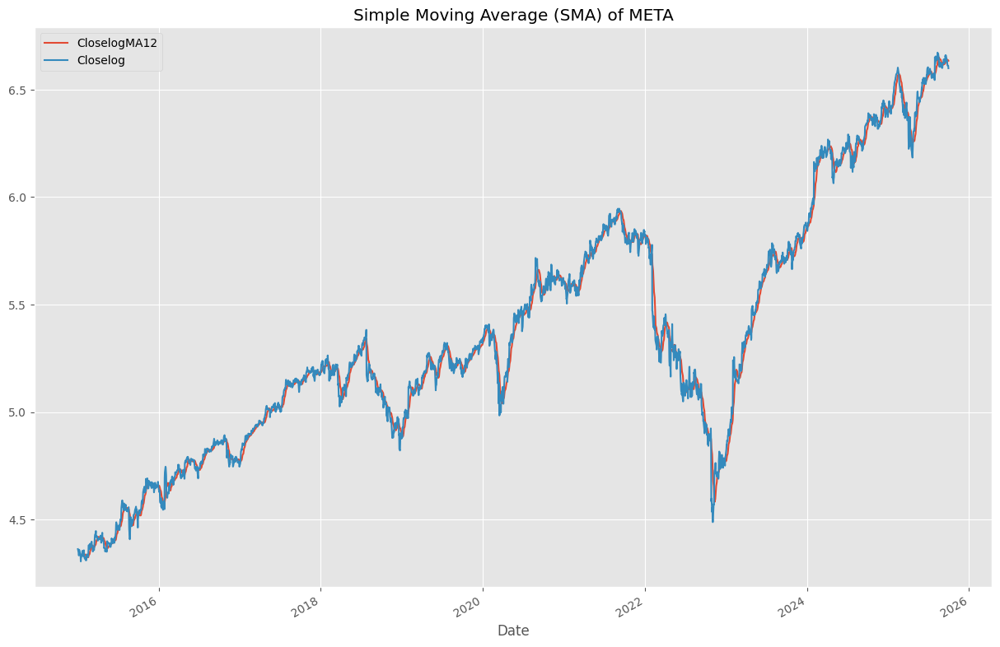

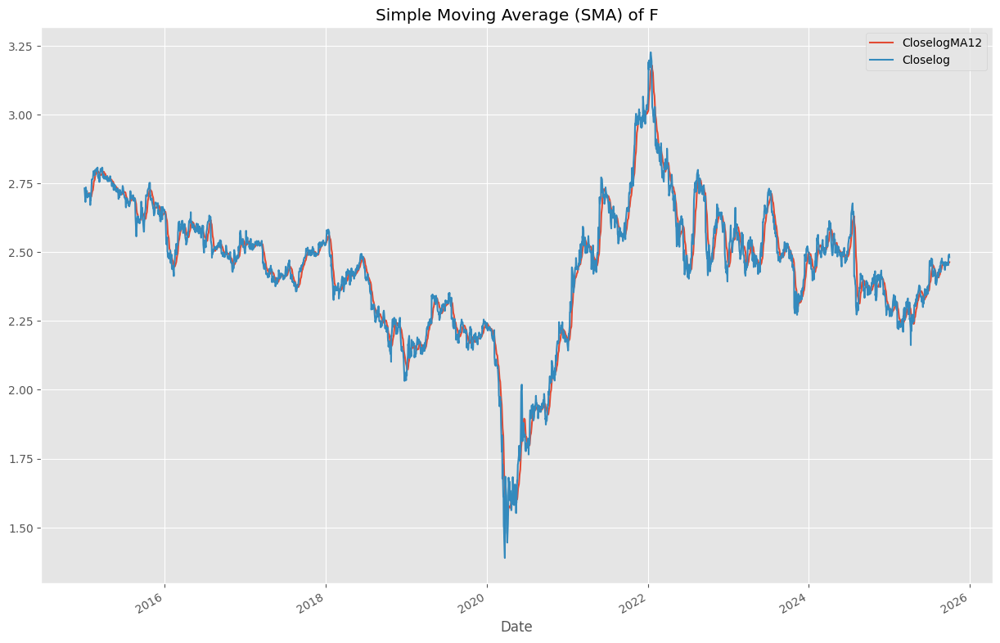

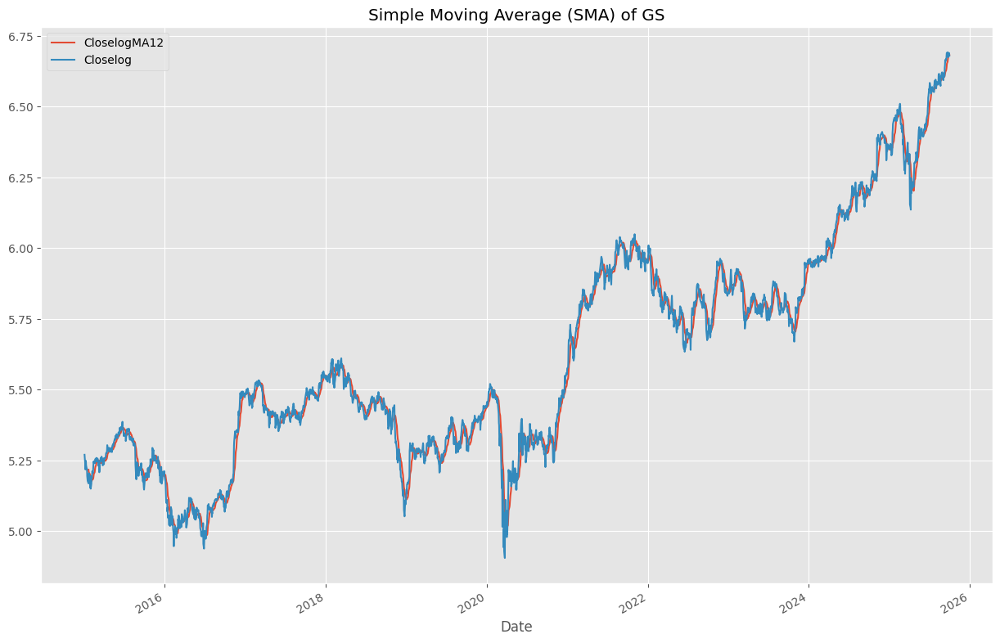

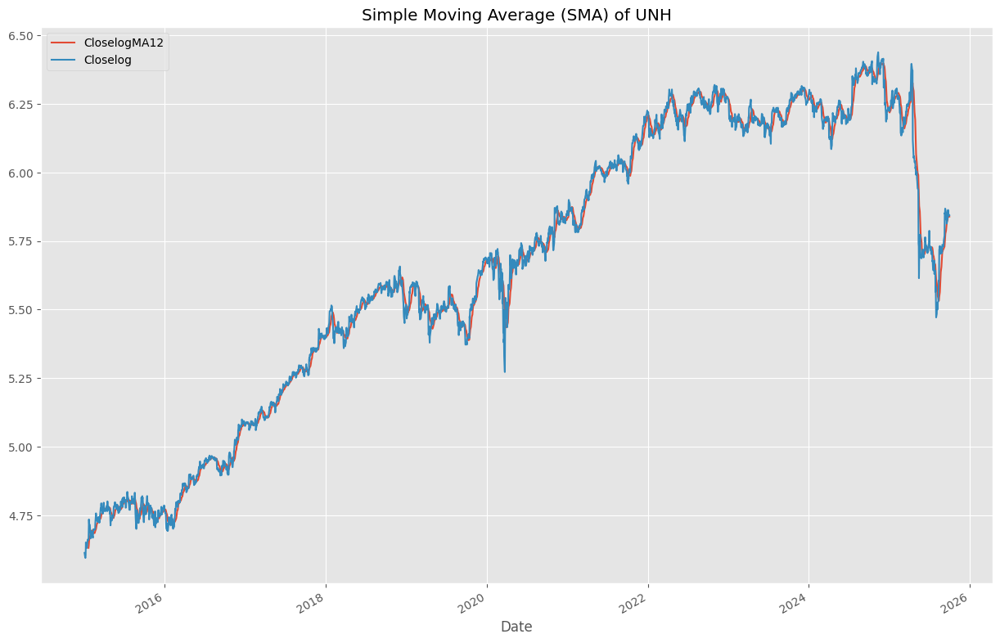

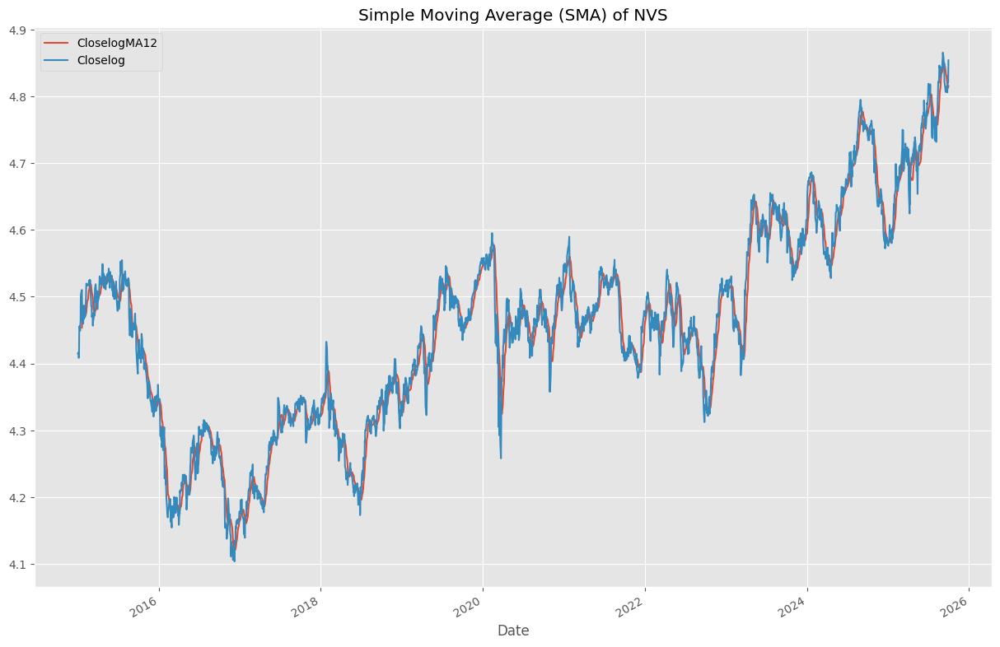

...

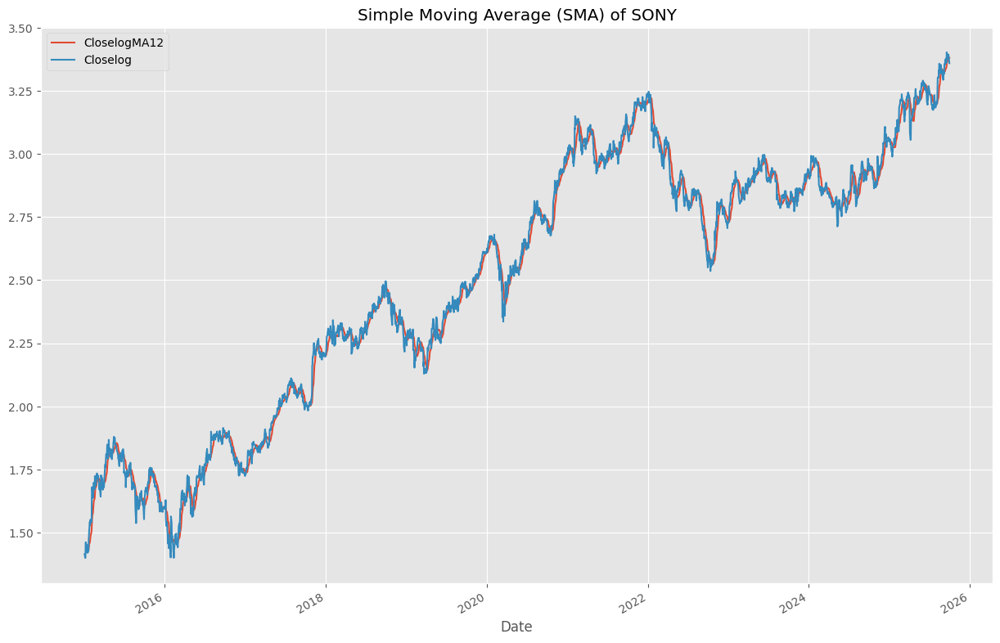

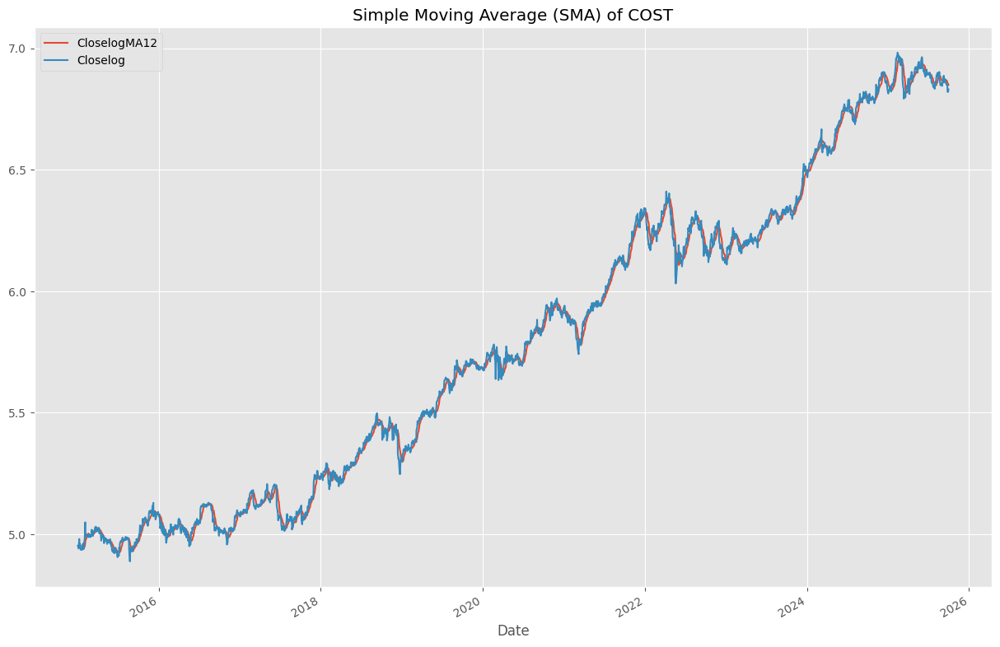

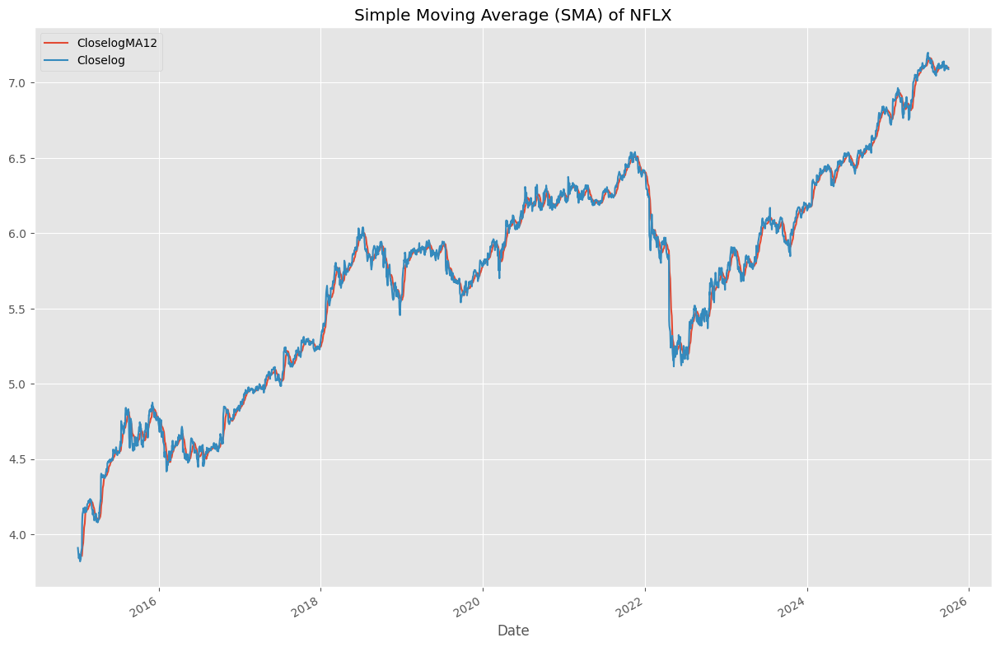

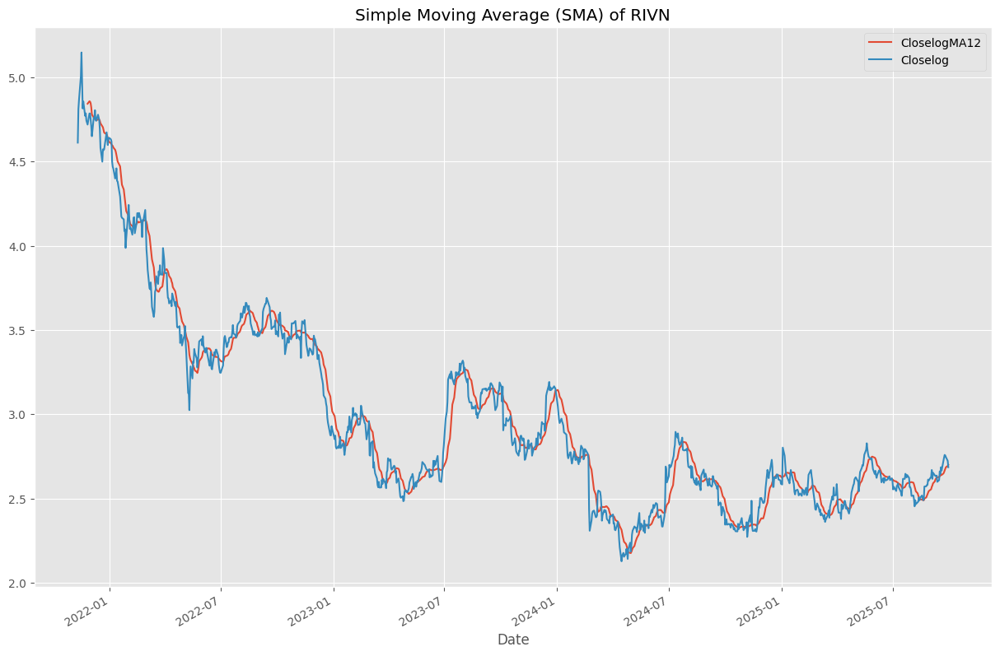

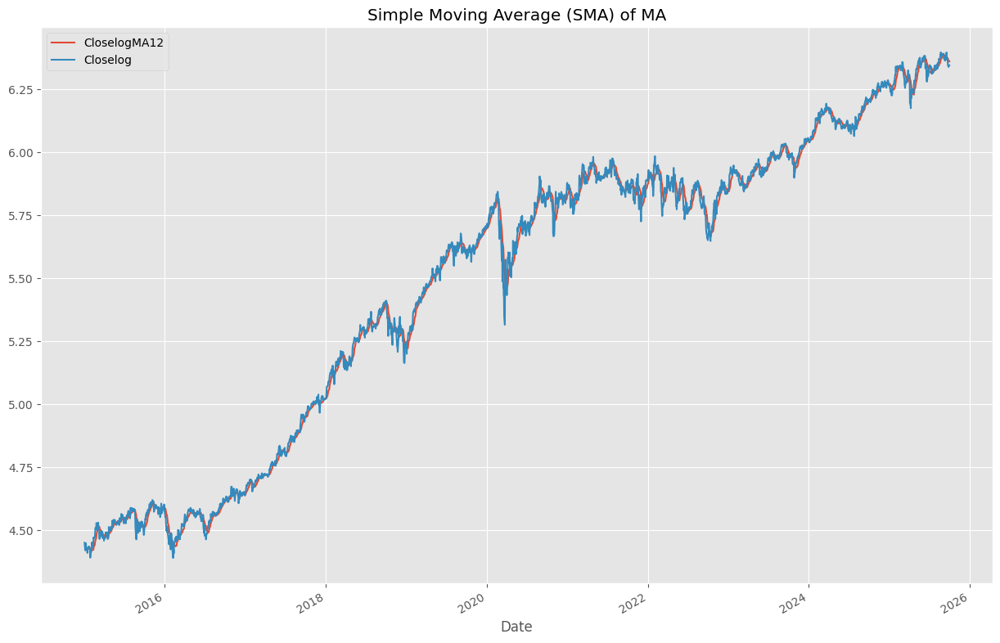

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (15, 10)

def adf(ts, name):
    rolmean = ts.rolling(window=12).mean()
    rolstd = ts.rolling(window=12).std()

    orig = plt.plot(ts.values, color='blue',label='Original')
    mean = plt.plot(rolmean.values, color='red', label='Rolling Mean')
    std = plt.plot(rolstd.values, color='black', label = 'Rolling Std')
    plt.legend(loc='best')
    plt.title(f"Rolling Mean & Standard Deviation for {name}")
    plt.show(block=False)

    adftest = adfuller(ts, autolag='AIC')
    adfoutput = pd.Series(adftest[0:4], index=['Test Statistic','p-value','# of Lags Used',
                                              'Number of Observations Used'])
    for key,value in adftest[4].items():
        adfoutput['Critical Value (%s)'%key] = value
    return adfoutput

for ticker in df_signal.keys():
    if ticker == 'Summary': continue
    df_signal[ticker]['CloselogMA12'] = df_signal[ticker]['Closelog'].rolling(window=12).mean()
    df_signal[ticker].plot(kind = "line", y = ["CloselogMA12", "Closelog"],
                           title = f"Simple Moving Average (SMA) of {ticker}")

**Thống kê kiểm định ADF**

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller

def kiem_dinh_tinh_dung_adf(chuoi_thoi_gian: pd.Series, name: str):
    """
    Thực hiện kiểm định Augmented Dickey-Fuller (ADF) để kiểm tra tính dừng.

    Args:
        chuoi_thoi_gian (pd.Series): Chuỗi thời gian cần kiểm tra (đã được làm sạch NaN).
        name (str): Tên của chuỗi thời gian (ví dụ: Ticker) để in ra kết quả.

    Returns:
        tuple (float, float, dict): Thống kê ADF, giá trị p, và Giá trị tới hạn.
    """
    print(f"\n--- 📊 Kiểm định ADF cho Ticker: {name} ---")

    # Xử lý NaN (mặc dù đã dùng dropna (inplace=True) trước khi gọi hàm,
    # việc kiểm tra lại vẫn đảm bảo tính ổn định)
    ts_cleaned = chuoi_thoi_gian.dropna()

    # Kiểm tra nếu chuỗi thời gian bị rỗng sau khi loại bỏ NaN
    if ts_cleaned.empty:
        print(f"**LƯU Ý: Chuỗi thời gian cho {name} bị rỗng sau khi loại bỏ NaN. Bỏ qua kiểm định.**")
        return None, None, None
    if len(ts_cleaned) < 3:
        print(f"**LƯU Ý: Chuỗi thời gian Log Returns cho {name} có quá ít điểm ({len(ts_cleaned)} < 3). Bỏ qua kiểm định.**")
        return None, None, None

    # Thực hiện kiểm định ADF
    try:
        # autolag='AIC' sẽ tự động chọn số lượng độ trễ tối ưu dựa trên AIC
        ket_qua = adfuller(ts_cleaned, autolag='AIC')
    except Exception as e:
        print(f"**LỖI KHI GỌI ADFULLER cho {name}: {e}**")
        return None, None, None

    # Trích xuất kết quả
    adf_statistic = ket_qua[0]
    p_value = ket_qua[1]
    gia_tri_toi_han = ket_qua[4] # Index 4 chứa Dictionary các giá trị tới hạn

    print(f"Thông kê kiểm định ADF (ADF Statistic): {adf_statistic:.4f}")
    print(f"Giá trị p (p-value): {p_value:.4f}")

    # Đưa ra kết luận về tính dừng dựa trên p-value
    print("\n--- KẾT LUẬN ---")
    if p_value < 0.05:
        print("**✅ KẾT LUẬN: Chuỗi Dừng (Stationary). Bác bỏ giả thuyết null H0.**")
    else:
        print("**❌ KẾT LUẬN: Chuỗi KHÔNG Dừng (Non-Stationary). Không bác bỏ giả thuyết null H0.**")

    # In thêm giá trị tới hạn để kiểm tra chi tiết
    print("Giá trị tới hạn (Critical values):")
    for key, value in gia_tri_toi_han.items():
        print(f"  {key}: {value:.4f}")

    return adf_statistic, p_value, gia_tri_toi_han


print("--- BẮT ĐẦU KIỂM ĐỊNH TÍNH DỪNG CHO TẤT CẢ CÁC TICKER ---")

for ticker in df_signal.keys():
    if ticker == 'Summary': continue
    # 1. TÍNH TOÁN CHUỖI THỜI GIAN
    # Tạo chuỗi thời gian bằng cách lấy hiệu số
    try:
        # Đảm bảo các cột tồn tại trong DataFrame/Series của ticker
        ts = df_signal[ticker]['Closelog'].diff()
    except KeyError as e:
        print(f"**LƯU Ý: Không tìm thấy cột cần thiết trong dữ liệu {ticker}. Lỗi: {e}**")
        continue

    # 2. CHẠY KIỂM ĐỊNH
    # Gọi hàm đã sửa lỗi
    kiem_dinh_tinh_dung_adf(ts, ticker)

--- BẮT ĐẦU KIỂM ĐỊNH TÍNH DỪNG CHO TẤT CẢ CÁC TICKER ---

--- 📊 Kiểm định ADF cho Ticker: META ---
Thông kê kiểm định ADF (ADF Statistic): -17.6655
Giá trị p (p-value): 0.0000

--- KẾT LUẬN ---
**✅ KẾT LUẬN: Chuỗi Dừng (Stationary). Bác bỏ giả thuyết null H0.**
Giá trị tới hạn (Critical values):
  1%: -3.4328
  5%: -2.8626
  10%: -2.5673

--- 📊 Kiểm định ADF cho Ticker: F ---
Thông kê kiểm định ADF (ADF Statistic): -16.4958
Giá trị p (p-value): 0.0000

--- KẾT LUẬN ---
**✅ KẾT LUẬN: Chuỗi Dừng (Stationary). Bác bỏ giả thuyết null H0.**
Giá trị tới hạn (Critical values):
  1%: -3.4328
  5%: -2.8626
  10%: -2.5673

--- 📊 Kiểm định ADF cho Ticker: GS ---
Thông kê kiểm định ADF (ADF Statistic): -17.6622
Giá trị p (p-value): 0.0000

--- KẾT LUẬN ---
**✅ KẾT LUẬN: Chuỗi Dừng (Stationary). Bác bỏ giả thuyết null H0.**
Giá trị tới hạn (Critical values):
  1%: -3.4328
  5%: -2.8626
  10%: -2.5673

--- 📊 Kiểm định ADF cho Ticker: UNH ---
Thông kê kiểm định ADF (ADF Statistic): -11.6779
Giá trị 

### **2.2. ARIMA Models**

Như những gì ta đã rút ra được từ mô hình hồi quy tuyến tính đã thực hiện ở **LAB4**, ta nhận thấy rằng giá trị quá khứ cung cấp một cái nhìn sâu sắc về giá trị tương lại khi phân tích giá đóng cửa của một cổ phiếu

Ngoài ra, nhận thấy một cách trực quan cho ta một giả định lợi nhuận cổ phiếu dao động quanh một giá trị trung bình.

Khi ta kết hợp cả hai điều trên, xây dựng một mô hình ARIMA(p,d,q)

- **Xác định bậc d**: Từ kết quả kiểm định ADF, tất cả stock cho chuỗi *Log_returns* là chuỗi dừng nên **$d=1$**


#### **1. Xác định bậc p và q (Hàn tự tương quan)**

Phân tích ACF $\to$ xác định q(MA)
- Hàm ACF đo lường mối tương quan giữa một quan sát và các quan sát trễ
- Mô hình MA(q): Hàm ACF sẽ cắt đứt (trở về 0 hoặc nằm trong ngưỡng tin cậy) sau độ trễ q

Phân tích PACF $\to$ Xác định p(AR)
- Hàm PACF đo lường mối tương quan giữa một quan sát và các quan sát trễ, sau khi đã loại bỏ ảnh hưởng của các độ trễ trung gian.
- Mô hình AR(p): Hàm PACF sẽ cắt đứt sau độ trễ p

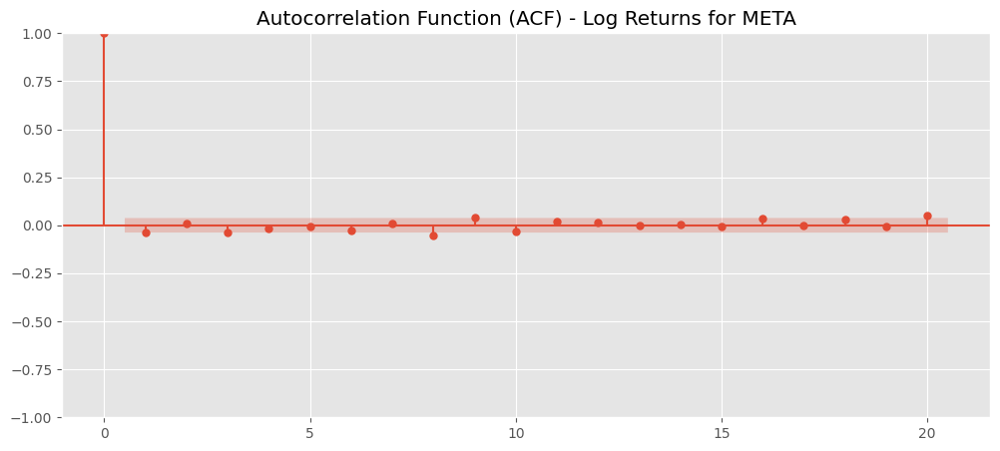

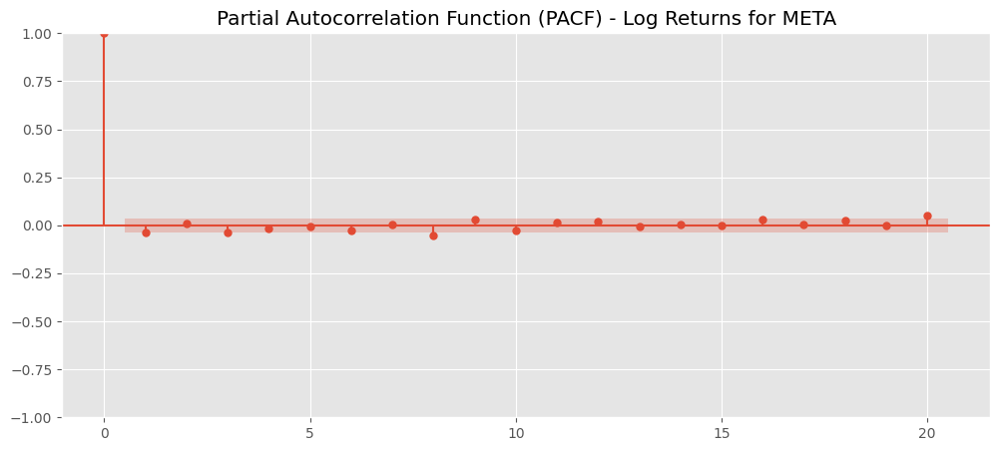

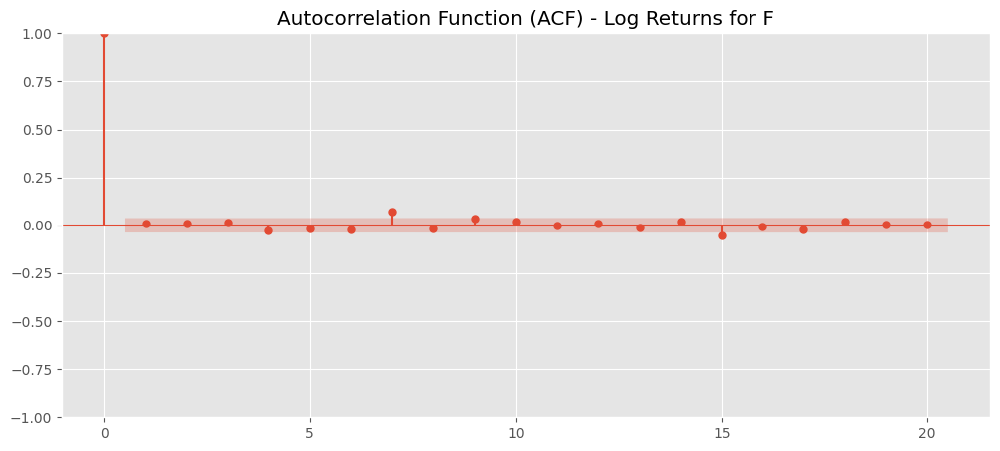

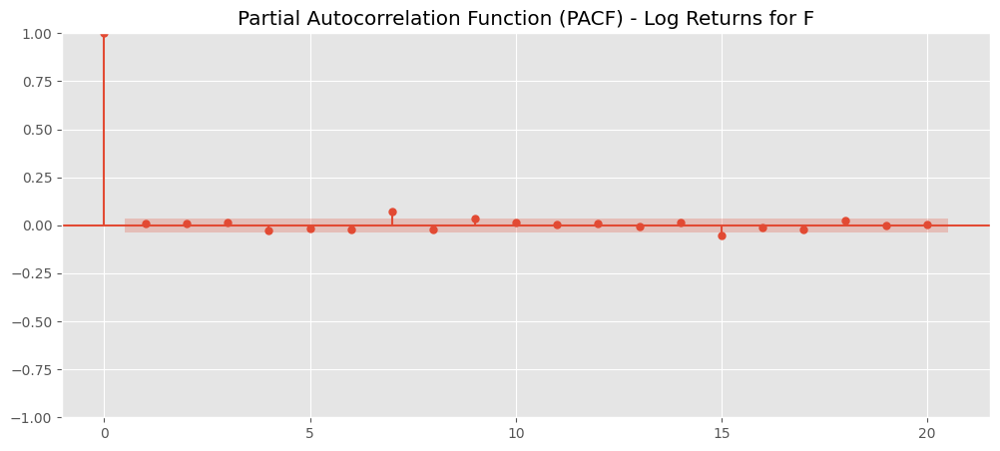

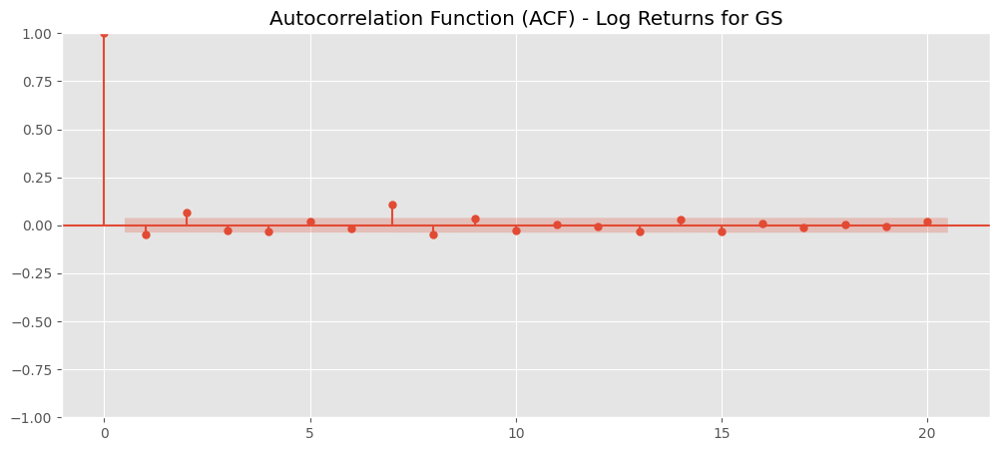

...

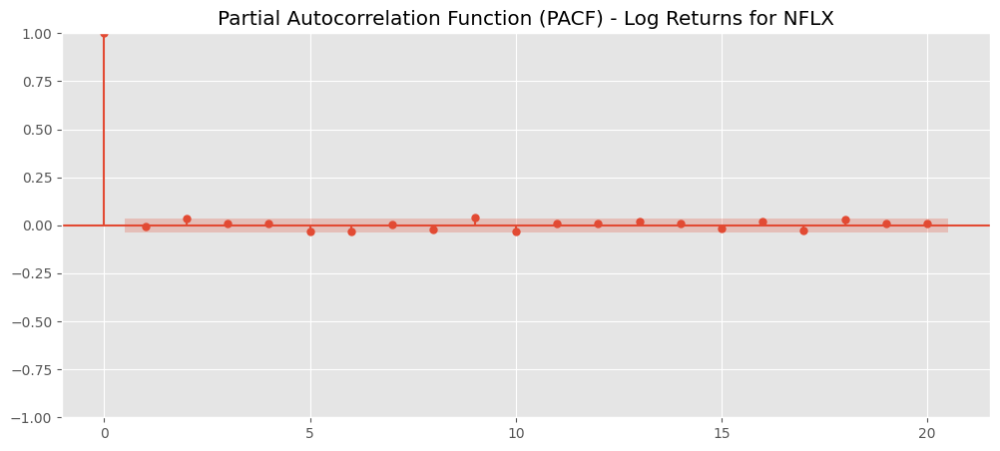

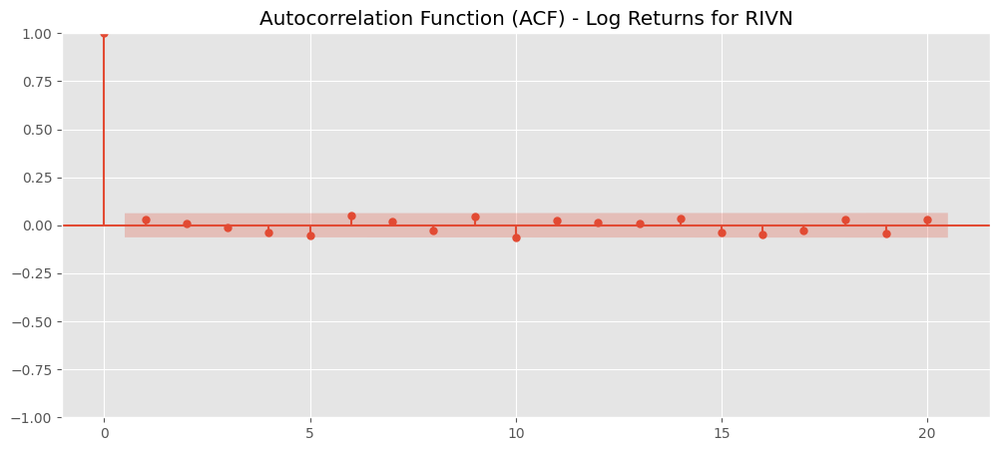

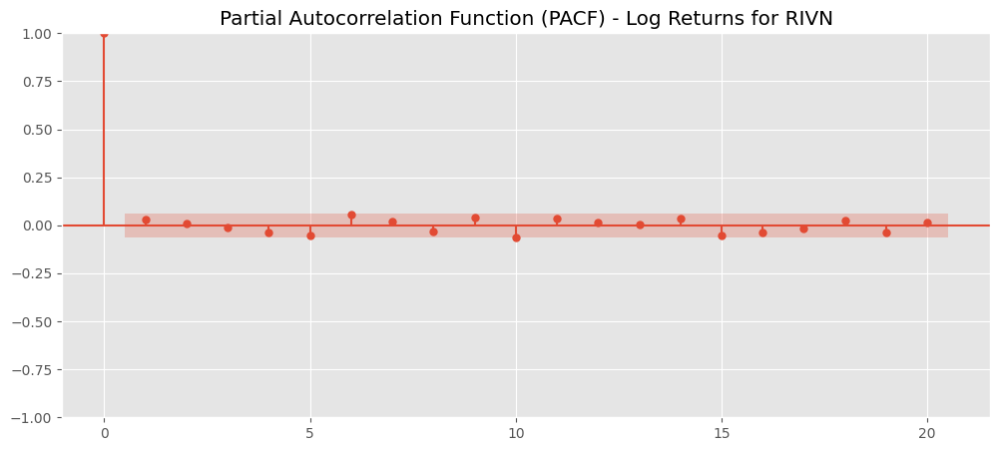

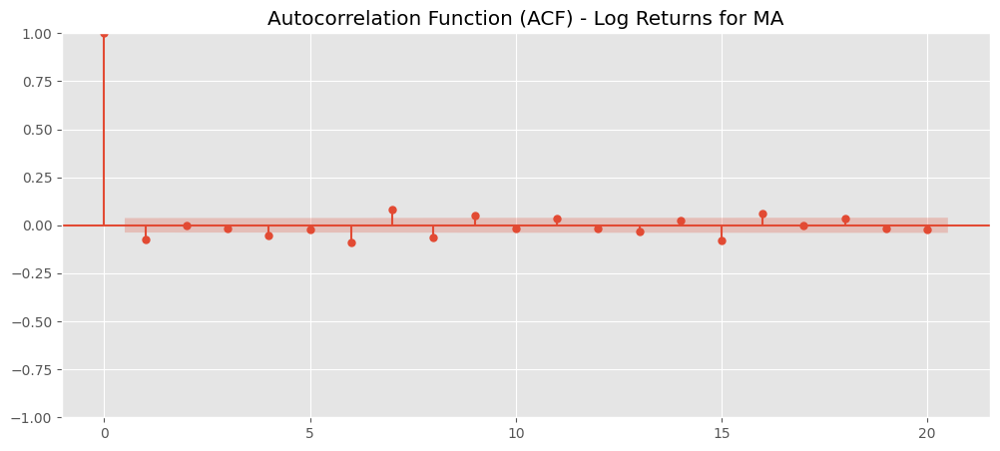

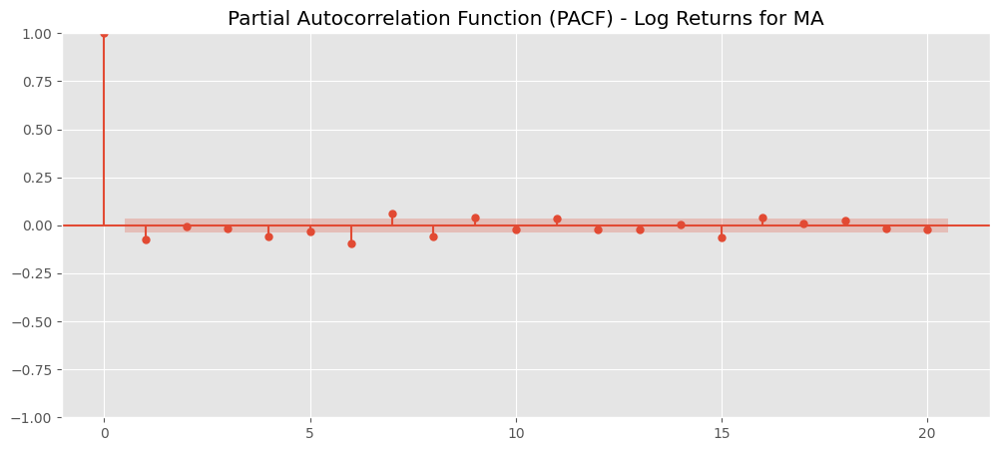

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Giả định: ticker_name là Ticker bạn đang phân tích (ví dụ: 'META')
# Giả định: log_returns là chuỗi Log Returns (Log Returns = df_signal[ticker_name]['Closelog'].diff().dropna())
for ticker_name in df_signal.keys():
    if ticker_name == 'Summary': continue
    log_returns = df_signal[ticker_name]['Closelog'].diff().dropna()
    # 1. Biểu đồ ACF -> Xác định q
    plt.figure(figsize=(12, 5))
    plot_acf(log_returns, lags=20, ax=plt.gca(), title=f"Autocorrelation Function (ACF) - Log Returns for {ticker_name}")
    plt.show()

    # 2. Biểu đồ PACF -> Xác định p
    plt.figure(figsize=(12, 5))
    plot_pacf(log_returns, lags=20, ax=plt.gca(), title=f"Partial Autocorrelation Function (PACF) - Log Returns for {ticker_name}")
    plt.show()

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
p, d, q = 0, 1, 0
order = (p, d, q)

for ticker in df_signal.keys():
  try:
    # 1. TRÍCH XUẤT DỮ LIỆU GỐC: df_signal[ticker]['Closelog']
    ts_original = df_signal[ticker]['Closelog']

    # 2. XỬ LÝ LỖI:
    #   a. Ép kiểu dữ liệu sang float
    #   b. Loại bỏ NaN và inf (ARIMA không xử lý được các giá trị này)
    #      (Mặc dù d=1 sẽ tự lấy sai phân, ARIMA vẫn cần xử lý chuỗi gốc)

    # Sử dụng .ffill() hoặc .bfill() nếu muốn điền khuyết (nhưng dropna() thường an toàn hơn)
    ts_cleaned = ts_original.replace([np.inf, -np.inf], np.nan).astype(float).dropna()

    # Kiểm tra nếu chuỗi rỗng sau khi làm sạch
    if ts_cleaned.empty:
        print(f"**LƯU Ý: Dữ liệu 'Closelog' cho {ticker} bị rỗng sau khi làm sạch. Bỏ qua mô hình.**")
        continue # Bỏ qua ticker này

    # 3. XÂY DỰNG VÀ HUẤN LUYỆN MÔ HÌNH
    # Dùng chuỗi gốc đã được làm sạch, bậc d=1 sẽ tự lấy sai phân
    model = ARIMA(ts_cleaned, order=(p, d, q))

    results = model.fit()

    # In tóm tắt kết quả
    print(f"\n--- Tóm tắt Mô hình ARIMA({p},{d},{q}) cho {ticker} ---")
    print(results.summary())

  except KeyError:
    print(f"**LỖI: Không tìm thấy khóa 'Closelog' cho ticker {ticker}.**")
  except Exception as e:
    print(f"**LỖI KHÁC KHI XÂY DỰNG/HUẤN LUYỆN mô hình ARIMA cho {ticker}: {e}**")

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



--- Tóm tắt Mô hình ARIMA(0,1,0) cho META ---
                               SARIMAX Results                                
Dep. Variable:               Closelog   No. Observations:                 2702
Model:                 ARIMA(0, 1, 0)   Log Likelihood                6252.797
Date:                Mon, 17 Nov 2025   AIC                         -12503.593
Time:                        16:13:45   BIC                         -12497.692
Sample:                             0   HQIC                        -12501.459
                               - 2702                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0006   4.16e-06    137.231      0.000       0.001       0.001
Ljung-Box (L1) (Q):                   3.89   Jarque-Bera (JB):             77111.95


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



--- Tóm tắt Mô hình ARIMA(0,1,0) cho GS ---
                               SARIMAX Results                                
Dep. Variable:               Closelog   No. Observations:                 2702
Model:                 ARIMA(0, 1, 0)   Log Likelihood                6964.672
Date:                Mon, 17 Nov 2025   AIC                         -13927.343
Time:                        16:13:45   BIC                         -13921.442
Sample:                             0   HQIC                        -13925.209
                               - 2702                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0003   3.87e-06     87.173      0.000       0.000       0.000
Ljung-Box (L1) (Q):                   5.63   Jarque-Bera (JB):              9679.95
Pr

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



--- Tóm tắt Mô hình ARIMA(0,1,0) cho NVS ---
                               SARIMAX Results                                
Dep. Variable:               Closelog   No. Observations:                 2702
Model:                 ARIMA(0, 1, 0)   Log Likelihood                8053.302
Date:                Mon, 17 Nov 2025   AIC                         -16104.604
Time:                        16:13:46   BIC                         -16098.703
Sample:                             0   HQIC                        -16102.470
                               - 2702                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0002    2.1e-06     71.543      0.000       0.000       0.000
Ljung-Box (L1) (Q):                   3.88   Jarque-Bera (JB):              3569.60
P

... (47 outputs left out)


--- Tóm tắt Mô hình ARIMA(0,1,0) cho AMZN ---
                               SARIMAX Results                                
Dep. Variable:               Closelog   No. Observations:                 2702
Model:                 ARIMA(0, 1, 0)   Log Likelihood                6641.630
Date:                Mon, 17 Nov 2025   AIC                         -13281.260
Time:                        16:13:52   BIC                         -13275.359
Sample:                             0   HQIC                        -13279.126
                               - 2702                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0004   5.89e-06     72.656      0.000       0.000       0.000
Ljung-Box (L1) (Q):                   0.80   Jarque-Bera (JB):              3808.09


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



--- Tóm tắt Mô hình ARIMA(0,1,0) cho COST ---
                               SARIMAX Results                                
Dep. Variable:               Closelog   No. Observations:                 2702
Model:                 ARIMA(0, 1, 0)   Log Likelihood                7748.845
Date:                Mon, 17 Nov 2025   AIC                         -15495.690
Time:                        16:13:52   BIC                         -15489.788
Sample:                             0   HQIC                        -15493.555
                               - 2702                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0002   2.23e-06     84.705      0.000       0.000       0.000
Ljung-Box (L1) (Q):                   1.50   Jarque-Bera (JB):              8770.40


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


#### **2. Kết quả**

**Nhận xét**

- Từ các test (H) và (JB) được hiện thị trong phần **summary(model)** cho thấy với mức ý nghĩa 5%, phần dư có phương sai thay đổi và không có phân phối chuẩn
- Kiểm định Ljung-Box cho thấy p-value lớn hơn 0.05. Nghĩa là, với mức ý nghĩa 5%, cho thấy mô hình **ARIMA(0,1,0)** nắm bắt được mối tương quan tuyến tính trong chuỗi *Log_returns*

**Kết luận**: Mô hình *ARIMA(0,1,0)* là một mô hình hợp lí để mô tả *Log_returns* từ góc độ tương quan tuyến tính. Tuy nhiên, mô hình này hoàn toàn thất bại trong việc mô tả độ biến động và phân phối của phần dư.

**Đề xuất**: Xây dựng mô hình **ARCH/GARCH** để mô hình hóa phương sai thay đổi phần dư

#### **3. Có nên đưa ra quyết định mua bán trực tiếp với mô hình ARIMA trên.**

Câu trả lời là không. Vì

**1. Mô hình là Ramdom Walk**

Log_returns của ticker là White Noise(không có tự tương quan tuyến tính). Điều này có nghĩa là lợi nhuận trong quá khứ không có khả năng dự đoán lợi nhuận trong tương lai. Tức là mọi dự báo cho giá đóng cửa hôm nay bằng giá đóng cửa ngày hôm qua cộng với nhiễu ngẫu nhiên.

**2.Thất bại trong việc mô tả độ biến động**

Các kiểm định cho thấy phần dư có phương sai thay đổi và không có phân phối chuẩn. Có nghĩa là:

- Rủi ro không phải là hằng số. Mô hình ARIMA(0,1,0) chỉ mô tả được xu hướng/ trung bình của lợi nhuận mà hoàn toàn bỏ qua sự biến động(Volatility)

- Phần dư không có phân phối chuẩn cho thấy các sự kiện lớn xảy ra thường xuyên hơn mức mà một mô hình chuẩn có thể giải thích.

## **3. Volatility**

In [ ]:
df_signal_copy = df_signal.copy()

In [ ]:
del df_signal_copy['Summary']

In [ ]:
# Tính Historical Volatility (HV)
# Tính giá trị Log_Returns trung bình hàng ngày
# Xác định số ngày giao dịch trong năm
import numpy as np

# Số ngày trong cửa sổ tính toán
# Tùy theo chiến lược đầu tư dài hay ngắn mà chọn cửa sổ nào.
# Chọn cửa số 20
WINDOW = 20
TRADING_DAYS_PER_YEAR = 252

for ticker in df_signal_copy.keys():
    # 1. Tính DAILY VOLATILITY CUỘN (STD của 20 ngày trước đó)
    # Kết quả là một chuỗi (Series) với mỗi giá trị thay đổi theo ngày
    df_signal_copy[ticker]['Daily_Volatility_20D'] = df_signal_copy[ticker]['Log_Returns'].rolling(window=WINDOW).std()

    # 2. Niên hóa kết quả (thường dùng nhất)
    df_signal_copy[ticker]['Annualized_Volatility_20D'] = df_signal_copy[ticker]['Daily_Volatility_20D'] * np.sqrt(TRADING_DAYS_PER_YEAR)

# Lưu ý: 20 giá trị đầu tiên sẽ là NaN vì không đủ dữ liệu.

In [ ]:
# In 1 mã để kiểm tra
df_signal_copy['AAPL'].tail(10)

,Open,High,Low,Close,Adj Close,Volume,SMA_20,SMA_50,STD_20,STD_50,UpperBand_20,LowerBand_20,UpperBand_50,LowerBand_50,Log_Returns,Turnover,Momentum_120D,Closelog,Daily_Volatility_20D,Annualized_Volatility_20D
Date,,,,,,,,,,,,,,,,,,,,
2025-09-17,238.970001,240.100006,237.729996,238.990005,238.990005,46508000,232.747500,222.622083,5.011939,11.658468,242.771378,222.723622,245.939019,199.305147,0.003521,1.111495e+10,0.078308,5.476422,0.015034,0.238661
2025-09-18,239.970001,241.199997,236.649994,237.880005,237.880005,44249600,233.341000,223.161670,4.872992,11.729022,243.086984,223.595017,246.619715,199.703626,-0.004655,1.052610e+10,0.063235,5.471766,0.014239,0.226041
2025-09-19,241.229996,246.300003,240.210007,245.500000,245.500000,163741300,234.371001,223.828286,5.163371,12.034708,244.697742,224.044259,247.897703,199.758869,0.031531,4.019849e+10,0.121705,5.503297,0.015508,0.246177
2025-09-22,248.300003,256.640015,248.119995,256.079987,256.079987,105517400,235.787000,224.731473,6.859573,12.721229,249.506147,222.067854,250.173930,199.289016,0.042193,2.702089e+10,0.144672,5.545490,0.017603,0.279431
2025-09-23,255.880005,257.339996,253.580002,254.429993,254.429993,60275200,237.150500,225.652403,7.711832,13.172322,252.574163,221.726836,251.997047,199.307759,-0.006464,1.533582e+10,0.133447,5.539026,0.017720,0.281298
2025-09-24,255.220001,255.740005,251.039993,252.309998,252.309998,42303700,238.300500,226.521144,8.181692,13.472069,254.663883,221.937116,253.465282,199.577006,-0.008367,1.067365e+10,0.121948,5.530658,0.017967,0.285211
2025-09-25,253.210007,257.170013,251.710007,256.869995,256.869995,55202100,239.619499,227.460109,8.946886,13.920156,257.513272,221.725727,255.300420,199.619797,0.017912,1.417976e+10,0.236873,5.548570,0.018205,0.289003
2025-09-26,254.100006,257.600006,253.779999,255.460007,255.460007,46076300,240.764500,228.373670,9.447231,14.231692,259.658961,221.870038,256.837055,199.910286,-0.005504,1.177065e+10,0.307049,5.543066,0.018344,0.291208
2025-09-29,254.559998,255.000000,253.009995,254.429993,254.429993,40127700,241.878999,229.243458,9.687960,14.471440,261.254919,222.503080,258.186337,200.300579,-0.004040,1.020969e+10,0.340435,5.539026,0.018393,0.291976


**Nhận xét:**
Historical Volatility (HV) là một công cụ phân tích rủi ro quan trọng, nhưng nó không trực tiếp thiết kế chiến lược nên mua hay nên bán. Thay vào đó, HV được sử dụng để đánh giá rủi ro và xác định các điểm vào/ra dựa trên sự thay đổi của rủi ro đó.

Một số chiến lược mua bán cổ phiếu dựa **Volatility**: **position sizing** and **option pricing**

### **3.1. GARCH**: dự đoán Volatility (mở rộng của mô hình ARCH)

**Ứng dụng:**
- Dự báo độ biến động thị trường trong tương lai (Forecast future market volatility).
- Điều chỉnh chiến lược giao dịch một cách linh hoạt (Adjust trading strategies dynamically).
- Kích hoạt các chiến lược phù hợp trong giai đoạn biến động cao (Activate strategies during high-volatility periods).

**GARCH(m, n)**
- Chọn m = 1. Với m là số lượng bình phương lợi nhuận quá khứ ($r_{t-i}^2$) được đưa vào mô hình. Đại diện cho tác động của các "cú sốc" giá (tin tức, biến động bất ngờ) gần đây lên độ biến động hôm nay. Nếu $m=1$, mô hình chỉ quan tâm đến cú sốc của ngày hôm qua.
- Chọn n = 1. Với n là số lượng phương sai quá khứ ($\sigma_{t-j}^2$) được đưa vào mô hình. Nó đại diện cho tính "dai dẳng" của độ biến động. Tức là nếu thị trường đã biến động mạnh trong quá khứ, nó có xu hướng tiếp tục biến động mạnh hôm nay.


**Xây mô hình GARCH**

In [ ]:
!pip install arch
import pandas as pd
import numpy as np
from arch import arch_model
import matplotlib.pyplot as plt

def fit_garch_model(returns_data, m=1, n=1, dist='Normal'):
    """
    Hàm xây dựng và huấn luyện mô hình GARCH.

    Tham số:
    - returns_data: Chuỗi pandas Series chứa log returns của cổ phiếu.
    - m (int): Số lượng độ trễ của bình phương lợi nhuận quá khứ (ARCH term - tương ứng 'p' trong thư viện).
    - n (int): Số lượng độ trễ của phương sai quá khứ (GARCH term - tương ứng 'q' trong thư viện).
    - dist (str): Phân phối xác suất ('Normal', 't', 'skewt'...). Mặc định là chuẩn (Normal).

    Trả về:
    - model_result: Kết quả thống kê chi tiết sau khi fit.
    - conditional_volatility: Chuỗi độ biến động dự báo (Standard Deviation).
    """

    # 1. Xử lý dữ liệu: Rescale (nhân 100) để mô hình hội tụ tốt hơn
    # Thư viện arch khuyến nghị dữ liệu nên ở dạng phần trăm (ví dụ: 5.0 thay vì 0.05)
    scaled_returns = returns_data * 100

    # 2. Khởi tạo mô hình
    # m là ARCH term (shocks), n là GARCH term (variance)
    # Trong thư viện 'arch': p là ARCH term, q là GARCH term
    # => Vậy nên ta gán: p=m, q=n
    am = arch_model(scaled_returns,
                    vol='Garch',
                    p=m,
                    q=n,
                    mean='Zero', # Giả định mean return xấp xỉ 0 (thường đúng với daily returns)
                    dist=dist)

    # 3. Huấn luyện (Fit) mô hình
    print(f"Đang chạy mô hình GARCH({m},{n})...")
    res = am.fit(disp='off')

    # 4. Lấy độ biến động (chia lại cho 100 để về đơn vị gốc ban đầu)
    conditional_volatility = res.conditional_volatility / 100

    return res, conditional_volatility

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 41.2 MB/s eta 0:00:00


**Chạy mô hình cho các mã cổ phiếu**

In [ ]:
import numpy as np
from arch import arch_model
import warnings

# Tắt cảnh báo linh tinh để output gọn gàng
warnings.filterwarnings("ignore")

print(f"--- BẮT ĐẦU TÍNH GARCH CHO {len(df_signal_copy)} MÃ ---")

# Duyệt qua từng mã trong dictionary
for ticker, df in df_signal_copy.items():
    try:
        # 1. Lấy dữ liệu và làm sạch (bỏ NaN)
        # Lưu ý: Cần kiểm tra xem cột 'Log_Returns' có tồn tại không
        if 'Log_Returns' not in df.columns:
            print(f"⚠️ {ticker}: Không tìm thấy cột 'Log_Returns'. Bỏ qua.")
            continue

        # Lấy chuỗi returns sạch
        returns_clean = df['Log_Returns'].dropna()

        # 2. Scale dữ liệu (Nhân 100)
        # GARCH chạy tốt hơn với số lớn (ví dụ 1.5 thay vì 0.015)
        returns_scaled = returns_clean * 100

        # 3. Khởi tạo và Fit mô hình GARCH(1,1)
        # p=1 (Lag Return), q=1 (Lag Variance) -> Tương ứng m=1, n=1
        am = arch_model(returns_scaled, vol='Garch', p=1, q=1, mean='Zero', dist='Normal')

        # disp='off' để không in log chi tiết của từng bước tính toán
        res = am.fit(disp='off')

        # 4. Lấy kết quả và Scale ngược lại (Chia 100)
        # res.conditional_volatility là độ biến động dự báo
        estimated_volatility = res.conditional_volatility / 100

        # 5. Gán ngược lại vào DataFrame gốc
        # Dùng .loc và index để đảm bảo ngày nào đi vào đúng dòng ngày đó
        df.loc[returns_clean.index, 'GARCH_Vol'] = estimated_volatility

        print(f"✅ {ticker}: Xong (Last Vol: {estimated_volatility.iloc[-1]:.4f})")

    except Exception as e:
        print(f"❌ {ticker}: Lỗi - {str(e)}")

--- BẮT ĐẦU TÍNH GARCH CHO 66 MÃ ---
✅ META: Xong (Last Vol: 0.0159)
✅ F: Xong (Last Vol: 0.0161)
✅ GS: Xong (Last Vol: 0.0130)
✅ UNH: Xong (Last Vol: 0.0212)
✅ NVS: Xong (Last Vol: 0.0102)
✅ MRNA: Xong (Last Vol: 0.0387)
✅ BP: Xong (Last Vol: 0.0141)
✅ CRM: Xong (Last Vol: 0.0172)
✅ LCID: Xong (Last Vol: 0.0456)
✅ MCD: Xong (Last Vol: 0.0096)
✅ COTY: Xong (Last Vol: 0.0244)
✅ TSLA: Xong (Last Vol: 0.0322)
✅ JPM: Xong (Last Vol: 0.0108)
✅ SHOP: Xong (Last Vol: 0.0350)
✅ ORCL: Xong (Last Vol: 0.0424)
✅ SBUX: Xong (Last Vol: 0.0160)
✅ SNOW: Xong (Last Vol: 0.0349)
✅ BABA: Xong (Last Vol: 0.0334)
✅ ABBV: Xong (Last Vol: 0.0142)
✅ ULTA: Xong (Last Vol: 0.0194)
✅ CVX: Xong (Last Vol: 0.0139)
✅ MS: Xong (Last Vol: 0.0139)
✅ HD: Xong (Last Vol: 0.0103)
✅ WMT: Xong (Last Vol: 0.0107)
✅ ELF: Xong (Last Vol: 0.0367)
✅ NVDA: Xong (Last Vol: 0.0252)
✅ LOW: Xong (Last Vol: 0.0138)
✅ WBD: Xong (Last Vol: 0.0536)
✅ GM: Xong (Last Vol: 0.0149)
✅ XOM: Xong (Last Vol: 0.0140)
✅ COP: Xong (Last Vol: 0.01

**VD: 1 mã META**

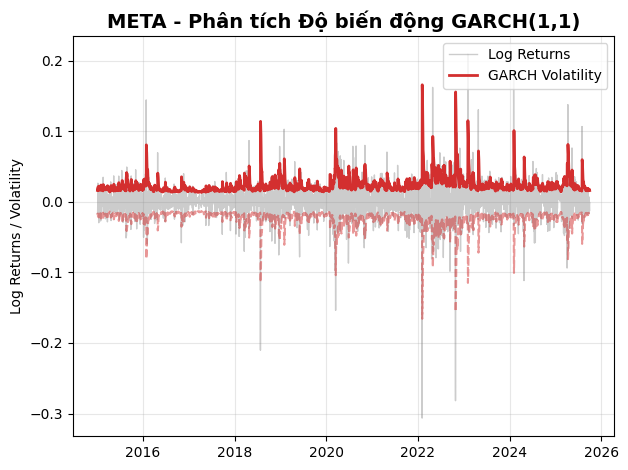

In [ ]:
# Chạy thử 1 mã:
import matplotlib.pyplot as plt

# --- CHỌN MÃ CẦN VẼ ---
ticker_to_plot = list(df_signal_copy.keys())[0]  # Mặc định lấy mã đầu tiên trong dict

# Lấy data của mã đó
df_plot = df_signal_copy[ticker_to_plot]

# Chỉ lấy dữ liệu những ngày đã chạy GARCH (bỏ những dòng NaN ban đầu)
plot_data = df_plot.dropna(subset=['GARCH_Vol'])

# --- BẮT ĐẦU VẼ ---

# BIỂU ĐỒ: Returns vs GARCH Volatility
# Vẽ Lợi nhuận (Returns) màu xám mờ để làm nền
plt.plot(plot_data.index, plot_data['Log_Returns'], color='grey', alpha=0.4, label='Log Returns', lw=1)
# Vẽ GARCH Volatility màu đỏ nổi bật
plt.plot(plot_data.index, plot_data['GARCH_Vol'], color='#D32F2F', label='GARCH Volatility', lw=2)
# Vẽ thêm đường âm của Volatility để tạo cảm giác biên độ
plt.plot(plot_data.index, -plot_data['GARCH_Vol'], color='#D32F2F', linestyle='--', alpha=0.5)

plt.title(f'{ticker_to_plot} - Phân tích Độ biến động GARCH(1,1)', fontsize=14, fontweight='bold')
plt.ylabel('Log Returns / Volatility')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Nhận xét:**

**1. Mô hình GARCH hoạt động rất tốt (Good Fit):**

  - Bắt được "Cụm biến động" (Volatility Clustering): Nhìn đường màu đỏ (Volatility). Nó không phẳng lỳ mà có những đợt "nổi sóng". Khi đường màu xám (Log Returns) dao động mạnh, đường màu đỏ lập tức dựng đứng lên. Điều này đúng với lý thuyết: "Biến động lớn thường kéo theo biến động lớn sau đó".

  - Phản ứng nhanh với cú sốc (Responsiveness): Nhìn vào các đường xám dài (giá sập mạnh). Ngay tại thời điểm đó, đường đỏ vọt lên cực đại. Mô hình không bị trễ nhịp (lag) quá nhiều.

**2. "Bắt mạch" lịch sử META qua các đỉnh Volatility**:

- Năm 2018 (Đỉnh nhỏ đầu tiên): Vụ scandal Cambridge Analytica khiến cổ phiếu lao dốc, độ biến động tăng vọt.

- Năm 2020 (Đỉnh giữa): Cú sập do COVID-19 (tháng 3/2020).

- Năm 2022 (Đỉnh cao nhất - Quan trọng nhất): Đây là giai đoạn kinh hoàng nhất của META (cổ phiếu chia 3, từ hơn 300 về dưới 100). Có ngày META sập tới 26% (tháng 2/2022).

Mô hình GARCH phản ánh cực chuẩn: Volatility vọt lên mức > 0.15 (15%). Nghĩa là mô hình dự báo mỗi ngày giá có thể dao động biên độ ±15%. Rủi ro cực đại.

**3. Tính chất "Hồi quy về trung bình" (Mean Reversion)**

Sau mỗi đợt dựng đứng (2018, 2020, 2022), đường màu đỏ đều từ từ hạ nhiệt và quay về mức nền thấp (khoảng 0.02 - 0.03).$\rightarrow$ Điều này xác nhận rằng META là cổ phiếu có tính chất Mean Reversion về độ biến động. Sau bão trời lại sáng.


**Vẽ đồ thị cho các mã còn lại**

⏳ Đang bắt đầu vẽ biểu đồ cho các mã (Trừ META)...


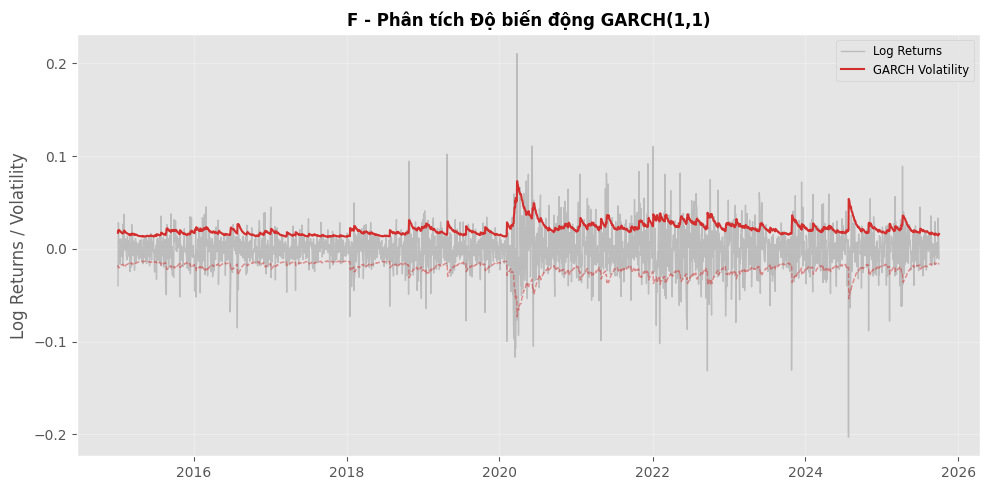

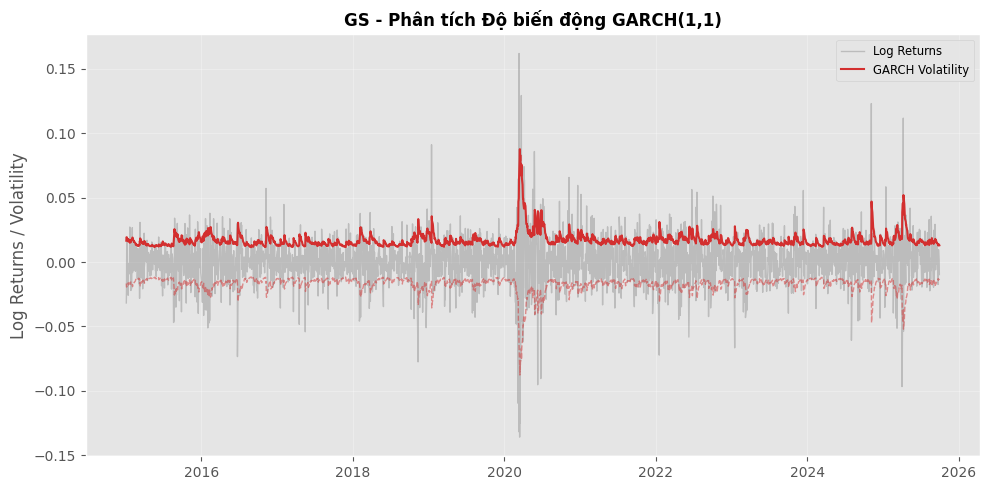

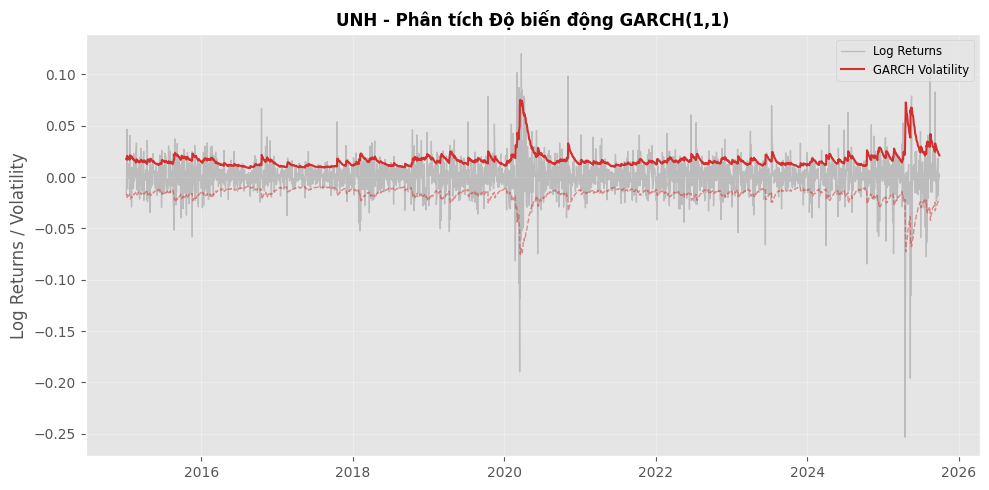

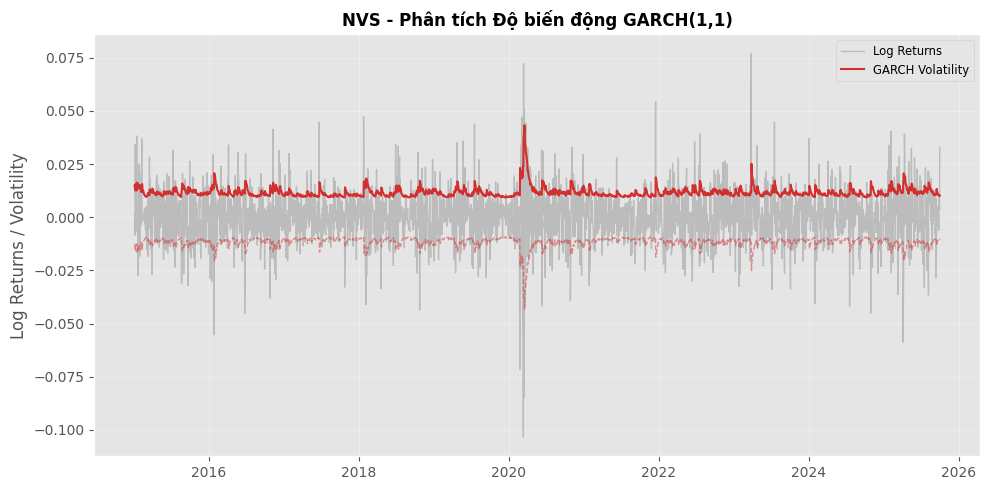

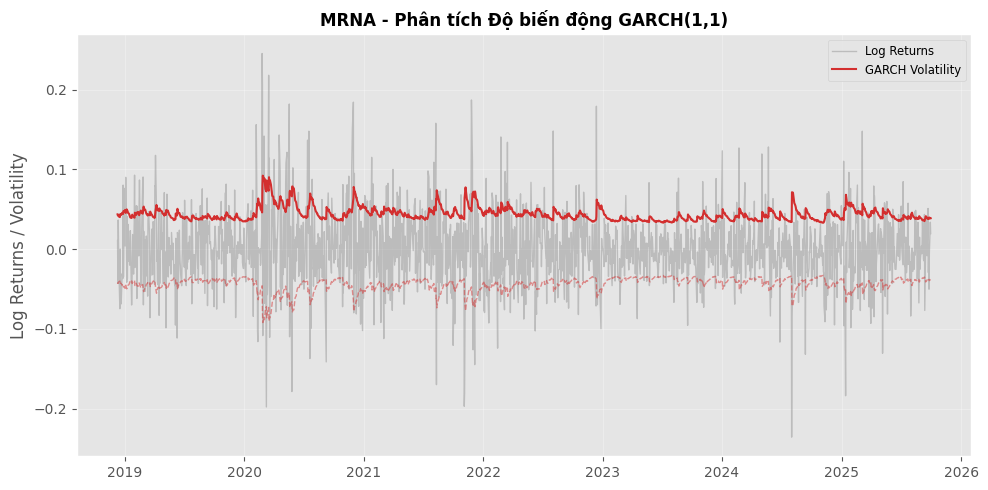

...

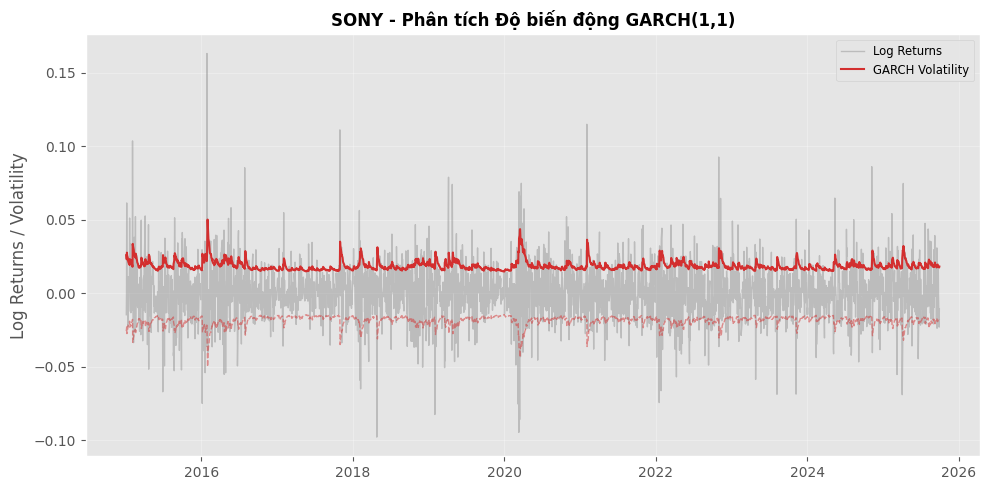

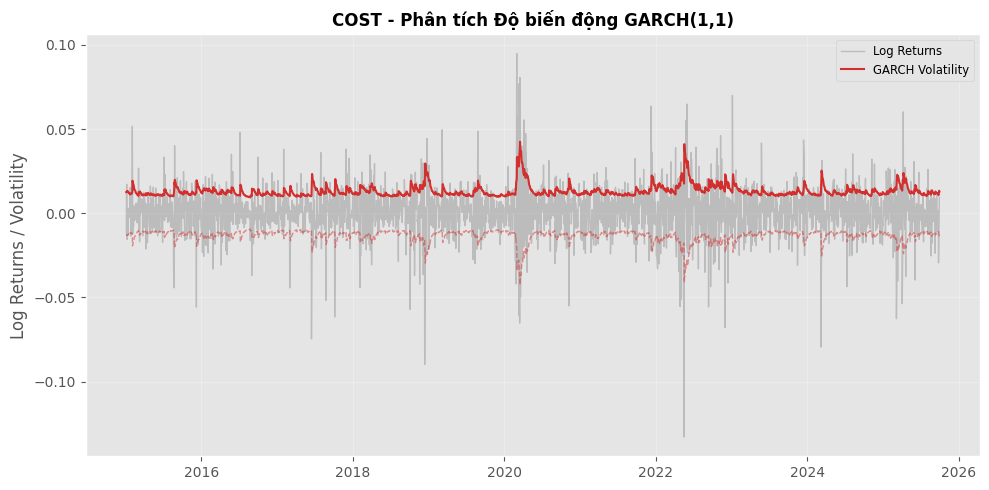

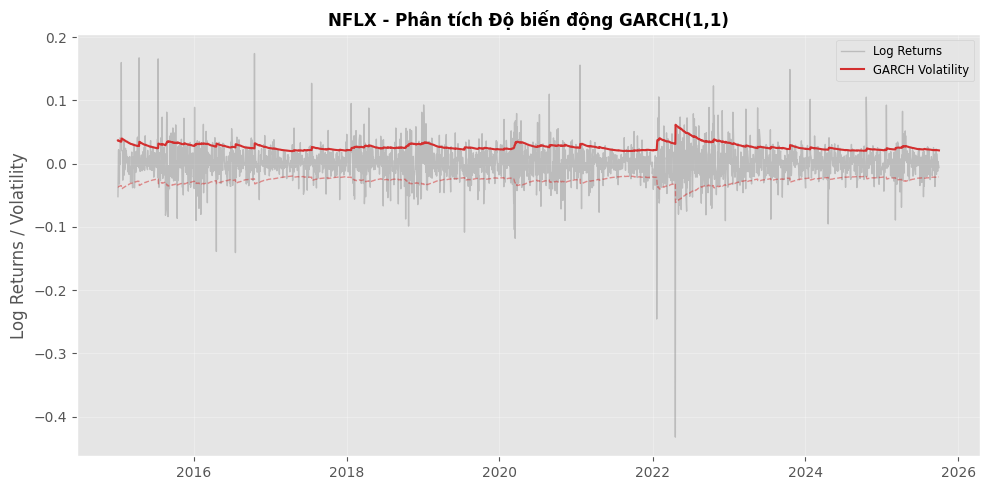

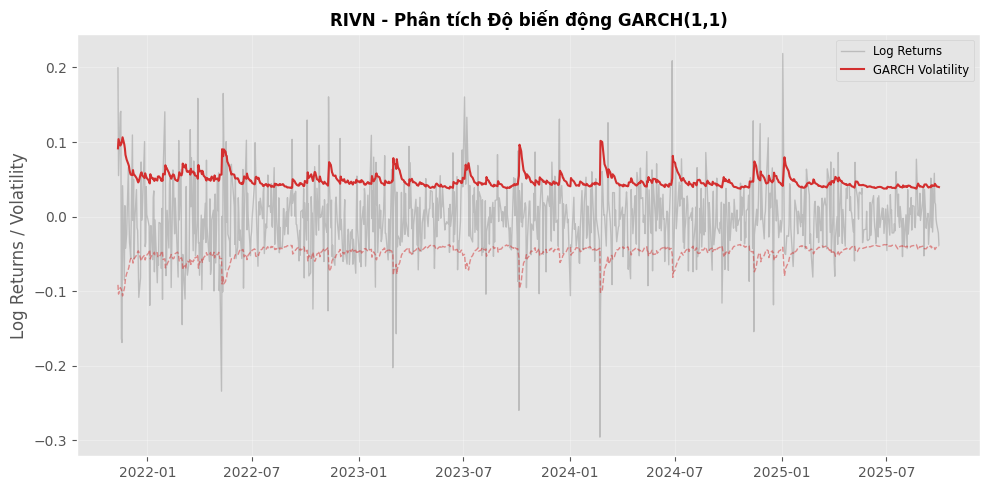

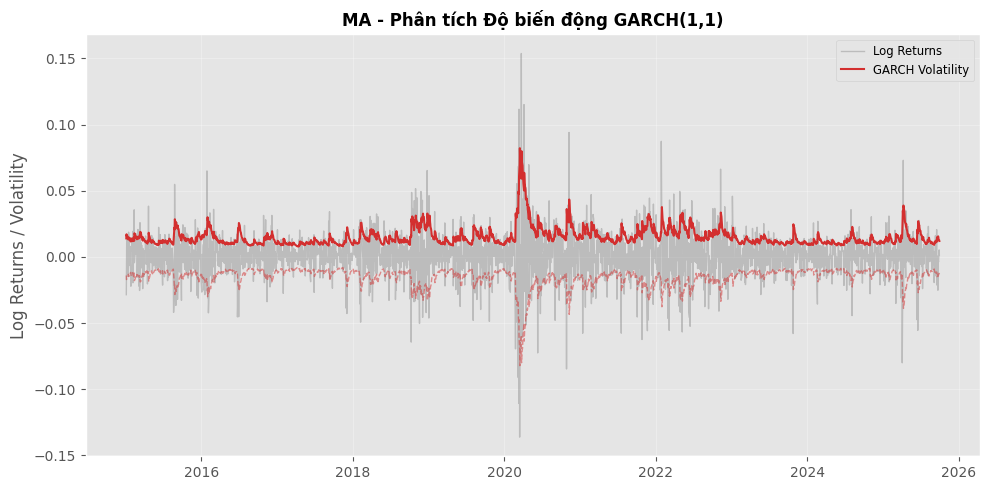

✅ Hoàn tất! Đã vẽ tổng cộng 65 biểu đồ.


In [ ]:
import matplotlib.pyplot as plt

# Đếm số lượng đã vẽ để theo dõi
count = 0

print("⏳ Đang bắt đầu vẽ biểu đồ cho các mã (Trừ META)...")

for ticker, df in df_signal_copy.items():

    if ticker == 'META':
        continue

    # Lấy dữ liệu sạch
    plot_data = df.dropna(subset=['GARCH_Vol', 'Log_Returns'])

    if plot_data.empty: continue

    # --- BẮT ĐẦU VẼ ---
    plt.figure(figsize=(10, 5))

    # Vẽ Lợi nhuận (Returns) làm nền
    plt.plot(plot_data.index, plot_data['Log_Returns'], color='grey', alpha=0.4, label='Log Returns', lw=1)

    # Vẽ GARCH Volatility (Biên trên)
    plt.plot(plot_data.index, plot_data['GARCH_Vol'], color='#D32F2F', label='GARCH Volatility', lw=1.5)

    # Vẽ GARCH Volatility (Biên dưới - đối xứng)
    plt.plot(plot_data.index, -plot_data['GARCH_Vol'], color='#D32F2F', linestyle='--', alpha=0.5, lw=1)

    # Trang trí
    plt.title(f'{ticker} - Phân tích Độ biến động GARCH(1,1)', fontsize=12, fontweight='bold')
    plt.ylabel('Log Returns / Volatility')
    plt.legend(loc='upper right', fontsize='small')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    # Hiển thị
    plt.show()
    count += 1

print(f"✅ Hoàn tất! Đã vẽ tổng cộng {count} biểu đồ.")

In [ ]:
df_signal_copy2 = df_signal_copy.copy()

### **3.2. Ứng dụng thực tế của Volatility**

Gồm: **Quản lý vốn (Position Sizing) và Volatility-Based Thresholds**

#### **1. Position Sizing (the number of shares to trade)**


Nguyên tắc: Biến động càng lớn thì mua càng ít lại.

- Nếu cổ phiếu đang "giật" mạnh (GARCH Vol cao), rủi ro lớn $\rightarrow$ Giảm số lượng cổ phiếu nắm giữ để nếu giá sập thì không lỗ quá mức chịu đựng.
- Nếu cổ phiếu êm đềm (GARCH Vol thấp) $\rightarrow$ Có thể mua nhiều hơn để tối ưu lợi nhuận.

Công thức:
$$ Số lượng cổ phiếu = \frac{\text{Số tiền chấp nhận mất (R)}}{\text{Giá hiện tại} \times \text{GARCH Volatility} \times \text{Hệ số an toàn}}$$

**Shift lịch lên để dự đoán nên mua bao nhiêu cho ngày hôm sau.**

In [ ]:
import pandas as pd

print("Thực hiện Shift ngày (Đẩy lịch lên 1 ngày)")

for ticker, df in df_signal_copy.items():
    # Kiểm tra xem Index có phải là ngày tháng không để tránh lỗi
    if isinstance(df.index, pd.DatetimeIndex):

        # SHIFT TOÀN BỘ INDEX LÊN 1 NGÀY
        # Dữ liệu ngày 30/9 sẽ biến thành ngày 01/10
        # Dữ liệu ngày 29/9 sẽ biến thành ngày 30/9
        df.index = df.index + pd.Timedelta(days=1)

        # Đổi tên cột giá cho đỡ nhầm lẫn
        # Vì bây giờ ngày 01/10 lại chứa giá của 30/9 -> Nên gọi là "Giá Hôm Qua" (Prev Close)
        mapper = {
            'Close': 'Prev_Close',
            'Adj Close': 'Prev_Adj_Close',
            'High': 'Prev_High',
            'Low': 'Prev_Low',
            'Open': 'Prev_Open',
            'Volume': 'Prev_Volume'
        }
        df.rename(columns=mapper, inplace=True)

        # Lưu lại vào dict
        df_signal_copy[ticker] = df

print("✅ Đã Shift xong! Bây giờ ngày trong bảng là 'Ngày Hành Động'.")

# --- KIỂM TRA LẠI KẾT QUẢ ---
ticker_check = list(df_signal_copy.keys())[0]
print(f"\nVí dụ mã {ticker_check} (5 dòng cuối):")
display(df_signal_copy[ticker_check].tail())

Thực hiện Shift ngày (Đẩy lịch lên 1 ngày)
✅ Đã Shift xong! Bây giờ ngày trong bảng là 'Ngày Hành Động'.

Ví dụ mã META (5 dòng cuối):


,Prev_Open,Prev_High,Prev_Low,Prev_Close,Prev_Adj_Close,Prev_Volume,SMA_20,SMA_50,STD_20,STD_50,...,Turnover,Momentum_120D,Closelog,Daily_Volatility_20D,Annualized_Volatility_20D,GARCH_Vol,MA_20,Upper_Band,Lower_Band,Signal
Date,,,,,,,,,,,,,,,,,,,,,
2025-09-25,757.500000,761.109985,752.530029,760.659973,760.659973,8828200,756.875635,748.806190,13.706275,25.997579,...,6.715258e+09,0.265849,6.634186,0.011206,0.177888,0.017607,756.875635,783.527917,730.223352,0
2025-09-26,753.450012,756.770020,744.549988,748.909973,748.909973,10591100,756.977338,749.735673,13.635534,25.121922,...,7.931780e+09,0.344134,6.618619,0.011590,0.183980,0.016806,756.977338,782.420495,731.534181,0
2025-09-27,750.000000,751.929993,737.349976,743.750000,743.750000,9696300,756.634668,750.591935,13.887925,24.134945,...,7.211623e+09,0.389125,6.611705,0.011633,0.184670,0.017867,756.634668,783.672920,729.596416,0
2025-09-30,748.719971,750.780029,739.150024,743.400024,743.400024,9246800,756.894580,751.383835,13.569796,23.199945,...,6.874071e+09,0.366087,6.611234,0.010992,0.174493,0.016992,756.894580,782.616170,731.172990,0
2025-10-01,742.250000,742.969971,726.299988,734.380005,734.380005,16226800,756.882874,751.821654,13.590115,22.651025,...,1.191664e+10,0.365178,6.599027,0.011294,0.179282,0.015936,756.882874,781.006979,732.758768,0


In [ ]:
def calculate_position_size(price, garch_vol, capital = 100_000_000, risk_per_trade=0.02):
    """
    price: Giá hiện tại của cổ phiếu
    garch_vol: Độ biến động dự báo từ GARCH (dạng số thập phân, ví dụ 0.015)
    capital: Tổng vốn
    risk_per_trade: Rủi ro chấp nhận cho mỗi lệnh (ví dụ 2% tài khoản)
    """
    # Số tiền tối đa chấp nhận mất cho lệnh này (ví dụ 2 triệu)
    risk_amount = capital * risk_per_trade

    # Khoảng biến động dự kiến của giá (ví dụ: Giá 100k, Vol 1.5% -> Biến động 1.5k)
    expected_move = price * garch_vol

    # Số cổ phiếu nên mua
    # Nếu biến động dự kiến là 1.5k, và ta chấp nhận mất 2 triệu -> Mua được 1333 cổ
    shares = risk_amount / expected_move

    return int(shares)

# Áp dụng trên tất cả các mã đã có
print(f"{'NGÀY':<12} | {'MÃ CP':<10} | {'GIÁ (CLOSE)':<15} | {'GARCH VOL':<15} | {'SL MUA KHUYẾN NGHỊ':<20} | {'GIÁ TRỊ LỆNH':<20}")
print("-" * 105)

for ticker, df in df_signal_copy.items():
    # Kiểm tra xem có cột cần thiết không
    if 'GARCH_Vol' in df.columns and 'Prev_Adj_Close' in df.columns:

        # Lấy dòng dữ liệu cuối cùng
        last_row = df.iloc[-1]

        # Giả sử index là dạng datetime
        date_val = last_row.name
        # Format lại cho đẹp (YYYY-MM-DD)
        date_str = date_val.strftime('%Y-%m-%d') if hasattr(date_val, 'strftime') else str(date_val)
        price = last_row['Prev_Adj_Close']
        vol = last_row['GARCH_Vol']

        # Gọi hàm để tính
        # Giả sử vốn 100 triệu, chịu rủi ro 2% mỗi lệnh
        shares = calculate_position_size(price, vol, capital=100_000_000, risk_per_trade=0.02)

        # Tính tổng tiền bỏ ra để mua số cổ này
        position_value = shares * price

        # In kết quả
        print(f"{date_str:<12} |{ticker:<10} | {price:<15,.0f} | {vol:<15.2%} | {shares:<20} | {position_value:<20,.0f}")

    else:
        print(f"⚠️ {ticker}: Thiếu dữ liệu Close hoặc GARCH_Vol")

NGÀY         | MÃ CP      | GIÁ (CLOSE)     | GARCH VOL       | SL MUA KHUYẾN NGHỊ   | GIÁ TRỊ LỆNH        
---------------------------------------------------------------------------------------------------------
2025-10-01   |META       | 734             | 1.59%           | 170889               | 125,497,465         
2025-10-01   |F          | 12              | 1.61%           | 10478700             | 123,892,418         
2025-10-01   |GS         | 796             | 1.30%           | 193050               | 153,735,363         
2025-10-01   |UNH        | 345             | 2.12%           | 273817               | 94,549,007          
2025-10-01   |NVS        | 128             | 1.02%           | 1532331              | 196,506,136         
2025-10-01   |MRNA       | 26              | 3.87%           | 2003127              | 51,740,770          
2025-10-01   |BP         | 34              | 1.41%           | 4123316              | 142,089,466         
2025-10-01   |CRM        | 237       

**Nhận xét:** đúng với nguyên tắc.

Mã nào có GARCH Vol thấp (An toàn) $\rightarrow$ Hàm sẽ bảo mua nhiều cổ phiếu (Giá trị lệnh lớn).

Mã nào có GARCH Vol cao (Rủi ro) $\rightarrow$ Hàm sẽ bảo mua ít cổ phiếu lại để nếu giá sập thì cũng chỉ mất đúng 2 triệu (2% vốn) như đã định.


#### **2. Volatility-Based Thresholds**


Dùng độ biến động để đặt ngưỡng Chốt lời (Take Profit - TP) và Cắt lỗ (Stop Loss - SL).

- **Stop Loss (Cắt lỗ)**: Phải đặt ở ngoài vùng dao động bình thường của giá.

Công thức: Giá Mua - (k * GARCH_Vol * Giá Mua) (Thường k = 2).

- **Take Profit (Chốt lời)**: Đặt xa hơn rủi ro một chút (Reward/Risk ratio).

Công thức: Giá Mua + (k * Reward_Ratio * GARCH_Vol * Giá Mua).

**Hàm tính Stop Loss và Take Profit**

In [ ]:
def trade_setup_calculator(price, garch_vol, capital=100_000_000, risk_per_trade=0.02, direction='Long'):
    """
    Tính toán kèo giao dịch đầy đủ dựa trên GARCH.

    Tham số:
    - direction: 'Long' (Mua) hoặc 'Short' (Bán khống)
    - price: Giá hiện tại
    - garch_vol: Độ biến động dự báo (ví dụ 0.015)
    """
    if garch_vol == 0 or pd.isna(garch_vol):
        return None

    # 1. Xác định biên độ dao động (2 lần độ lệch chuẩn/volatility)
    stop_distance_pct = 2 * garch_vol  # Đặt Stoploss cách 2 lần biến động (Safety Zone)

    # 2. Tính mức giá Cắt lỗ (SL) và Chốt lời (TP)
    if direction == 'Long':
        stop_loss_price = price * (1 - stop_distance_pct)
        # Giả sử tỷ lệ Lời/Lỗ mục tiêu là 2:1
        take_profit_price = price * (1 + stop_distance_pct * 2)
    else: # Short
        stop_loss_price = price * (1 + stop_distance_pct)
        take_profit_price = price * (1 - stop_distance_pct * 2)

    # 3. Tính số lượng cổ phiếu (Position Sizing)
    # Công thức chuẩn: Số cổ = Tiền rủi ro / (Giá vào - Giá cắt lỗ)
    risk_money = capital * risk_per_trade
    price_risk_per_share = abs(price - stop_loss_price)

    shares = int(risk_money / price_risk_per_share)

    return {
        'Hành Động': direction,
        'Giá Vào': price,
        'Biến Động (Risk)': garch_vol,
        'Khối Lượng': shares,
        'Giá Trị Lệnh': shares * price,
        'Cắt Lỗ (SL)': stop_loss_price,
        'Chốt Lời (TP)': take_profit_price
    }

In [ ]:
# --- TẠO SIGNAL TRƯỚC (dựa vào MEAN REVERSION) ---
for ticker, df in df_signal_copy.items():
    # Tự động tìm tên cột giá
    if 'Prev_Adj_Close' in df.columns: col = 'Prev_Adj_Close'
    elif 'Adj Close' in df.columns: col = 'Adj Close'
    else: col = 'Close'

    # Gọi hàm tạo tín hiệu (Mean Reversion hoặc Breakout tùy chọn)
    # Ví dụ dùng Mean Reversion:
    if 'GARCH_Vol' in df.columns:
        # Tính lại Bands và Signal
        df['MA_20'] = df[col].rolling(20).mean()
        df['Upper_Band'] = df['MA_20'] * (1 + 2 * df['GARCH_Vol'])
        df['Lower_Band'] = df['MA_20'] * (1 - 2 * df['GARCH_Vol'])

        df['Signal'] = 0
        df.loc[df[col] < df['Lower_Band'], 'Signal'] = 1   # Mua
        df.loc[df[col] > df['Upper_Band'], 'Signal'] = -1  # Bán

        # Lưu lại vào dict
        df_signal_copy[ticker] = df

In [ ]:
# CHẠY VÒNG LẶP CHO TOÀN BỘ MÃ
trade_plans = []

for ticker, df in df_signal_copy.items():

    # A. Tìm cột giá (Ưu tiên cột đã Shift tên)
    if 'Prev_Adj_Close' in df.columns: price_col = 'Prev_Adj_Close'
    elif 'Prev_Close' in df.columns: price_col = 'Prev_Close'
    elif 'Adj Close' in df.columns: price_col = 'Adj Close'
    else: price_col = 'Close'

    # B. Kiểm tra dữ liệu
    if 'GARCH_Vol' in df.columns and price_col in df.columns:
        # Lấy dòng cuối
        last_row = df.iloc[-1]

        # Lấy ngày (Từ index)
        date_val = df.index[-1]
        date_str = str(date_val).split(' ')[0]

        price = last_row[price_col]
        vol = last_row['GARCH_Vol']

        # C. Xác định hướng (Long/Short)
        signal = last_row.get('Signal', 0)

        if signal == -1:
            trade_dir = 'Short'
            status = 'BÁN KHỐNG'
        elif signal == 1:
            trade_dir = 'Long'
            status = 'MUA NGAY'
        else:
            trade_dir = 'Long' # Mặc định tính chiều mua để tham khảo
            status = 'Theo Dõi'

        # D. Gọi hàm tính toán
        setup = trade_setup_calculator(price, vol, capital=100_000_000, risk_per_trade=0.02, direction=trade_dir)

        if setup:
            # Thêm thông tin bổ sung
            setup['Ngày'] = date_str
            setup['Mã CP'] = ticker
            setup['Trạng Thái'] = status

            trade_plans.append(setup)

# HIỂN THỊ KẾT QUẢ
if trade_plans:
    df_plan = pd.DataFrame(trade_plans)

    # Sắp xếp cột
    cols_order = ['Ngày', 'Mã CP', 'Trạng Thái', 'Hành Động', 'Giá Vào', 'Biến Động (Risk)', 'Khối Lượng', 'Giá Trị Lệnh', 'Cắt Lỗ (SL)', 'Chốt Lời (TP)']

    # Kiểm tra lần cuối xem cột có đủ không trước khi sort
    missing_cols = [c for c in cols_order if c not in df_plan.columns]
    if not missing_cols:
        df_plan = df_plan[cols_order]

        # Format hiển thị
        format_dict = {
            'Giá Vào': '{:,.0f}',
            'Giá Trị Lệnh': '{:,.0f}',
            'Cắt Lỗ (SL)': '{:,.0f}',
            'Chốt Lời (TP)': '{:,.0f}',
            'Biến Động (Risk)': '{:.2%}'
        }

        print("\n--- BẢNG KẾ HOẠCH GIAO DỊCH (TRADE PLAN) ---")
        try:
            display(df_plan.style.format(format_dict))
        except:
            print(df_plan.to_string(formatters={k: v.format for k, v in format_dict.items()}))
    else:
        print(f"Vẫn thiếu cột: {missing_cols}. Kiểm tra lại hàm calculate.")
else:
    print("Không có dữ liệu hợp lệ.")


--- BẢNG KẾ HOẠCH GIAO DỊCH (TRADE PLAN) ---


,Ngày,Mã CP,Trạng Thái,Hành Động,Giá Vào,Biến Động (Risk),Khối Lượng,Giá Trị Lệnh,Cắt Lỗ (SL),Chốt Lời (TP)
0,2025-10-01,META,Theo Dõi,Long,734,1.59%,85444,"62,748,365",711,781
1,2025-10-01,F,Theo Dõi,Long,12,1.61%,5239350,"61,946,209",11,13
2,2025-10-01,GS,Theo Dõi,Long,796,1.30%,96525,"76,867,681",776,838
3,2025-10-01,UNH,Theo Dõi,Long,345,2.12%,136908,"47,274,331",331,375
4,2025-10-01,NVS,BÁN KHỐNG,Short,128,1.02%,766165,"98,253,004",131,123
5,2025-10-01,MRNA,Theo Dõi,Long,26,3.87%,1001563,"25,870,372",24,30
6,2025-10-01,BP,Theo Dõi,Long,34,1.41%,2061658,"71,044,733",33,36
7,2025-10-01,CRM,Theo Dõi,Long,237,1.72%,246006,"58,303,422",229,253
8,2025-10-01,LCID,BÁN KHỐNG,Short,24,4.56%,922430,"21,944,611",26,19
9,2025-10-01,MCD,Theo Dõi,Long,304,0.96%,341814,"103,873,861",298,316


### **3.3. Trading Strategies Using Bollinger Bands**

**Xây chiến lược Mua/Bán dựa vào Bollinger Bands (Signal)**

**BackTest**: cho Mean Reversion của Bollinger Bands

Đang chạy Backtest chiến lược Mean Reversion...

=== BẢNG KẾT QUẢ BACKTEST TOÀN BỘ 66 MÃ ===
   Ticker  Strategy Return  Market Return  Win vs Market
42    NOW        1,163.32%      1,265.81%          False
3     UNH          229.68%        306.00%          False
19   ULTA          203.63%        331.05%          False
47  CMCSA          203.34%         39.69%           True
49   SHEL          164.76%         85.39%           True
31   INTC          144.04%         20.27%           True
33      V          121.57%        455.43%          False
61   SONY          121.10%        644.97%          False
16   SNOW          120.99%        -11.18%           True
37  LRLCY          119.65%        213.37%          False
53     KO          111.54%        121.12%          False
52   MSFT          109.02%      1,197.05%          False
48   GOOG           98.18%        837.06%          False
13   SHOP           85.26%      8,641.76%          False
65     MA           77.16%        609.14%          F

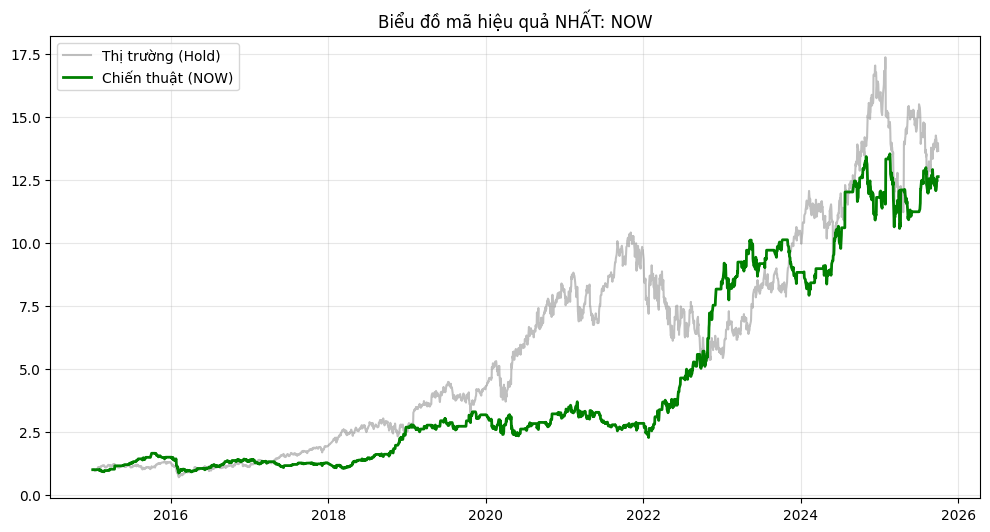


Thông tin thêm:
- Mã tốt nhất: NOW (Lãi: 1163.32%)
- Mã tệ nhất: TSLA (Lãi: -90.36%)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def backtest_mean_reversion(df, initial_capital=100_000_000):
    # 1. Tìm tên cột giá (Chống lỗi Key Error)
    if 'Adj Close' in df.columns:
      col_price = 'Adj Close'
    elif 'Close' in df.columns:
      col_price = 'Close'
    else:
      return None

    # Kiểm tra cột GARCH
    if 'GARCH_Vol' not in df.columns:
      return None

    # 2. Xây dựng Dynamic Bollinger Bands
    # Đường giữa (MA 20 ngày)
    df['MA_20'] = df[col_price].rolling(window=20).mean()

    # Dải băng trên/dưới dùng GARCH Volatility (Mean +/- 2*Vol)
    # Lưu ý: GARCH Vol là log return vol, ta nhân với giá để ra biên độ tuyệt đối
    # Hoặc đơn giản hóa: Upper = MA * (1 + 2*Vol)
    df['Upper_Band'] = df['MA_20'] * (1 + 2 * df['GARCH_Vol'])
    df['Lower_Band'] = df['MA_20'] * (1 - 2 * df['GARCH_Vol'])

    # 3. Logic vào lệnh (Mean Reversion)
    # Signal = 1 (Giữ Mua), 0 (Tiền mặt)
    df['Signal'] = 0

    # MUA khi Giá < Lower Band
    df.loc[df[col_price] < df['Lower_Band'], 'Signal'] = 1

    # BÁN (Thoát vị thế) khi Giá > MA_20 (Hồi về trung bình là chốt)
    # Hoặc giữ lệnh cho đến khi có tín hiệu bán
    # Ở đây ta làm đơn giản: Nếu Giá > Upper Band thì ép bán (Signal = 0)
    # Còn nằm giữa thì giữ nguyên trạng thái hôm trước (Forward Fill)

    # Tạo cột Long_Entry và Long_Exit riêng để xử lý giữ lệnh
    long_entry = df[col_price] < df['Lower_Band']
    long_exit = df[col_price] > df['MA_20'] # Chốt lời sớm khi về tham chiếu

    # Entry: Giá vọt lên trên Dải trên -> Bán khống ngay đỉnh
    short_entry = df[col_price] > df['Upper_Band']
    # Exit: Giá rớt về lại đường trung bình -> Mua trả hàng (Chốt lời Short)
    short_exit = df[col_price] < df['MA_20']

    # Logic giữ lệnh (State Machine)
    position = 0
    positions = []
    for i in range(len(df)):
      # --- ĐANG CẦM TIỀN (0) ---
      if position == 0:
        if long_entry.iloc[i]:
          position = 1   # Bắt đáy
        elif short_entry.iloc[i]:
          position = -1  # Bán đỉnh (Short)

      # --- ĐANG GIỮ MUA (1) ---
      elif position == 1:
        if long_exit.iloc[i]:
          position = 0   # Chốt lời Mua

      # --- ĐANG GIỮ BÁN (-1) ---
      elif position == -1:
        if short_exit.iloc[i]:
          position = 0   # Chốt lời Short (Cover)

      positions.append(position)

    df['Position'] = positions

    # 4. Tính Lãi/Lỗ (Shift 1 ngày: Tín hiệu hôm nay -> Lời lỗ ngày mai)
    df['Strategy_Returns'] = df['Position'].shift(1) * df['Log_Returns']

    # Tổng kết
    df['Cumulative_Strategy'] = df['Strategy_Returns'].cumsum().apply(np.exp)
    df['Cumulative_Market'] = df['Log_Returns'].cumsum().apply(np.exp)

    return df

# --- CHẠY BACKTEST ---
print("Đang chạy Backtest chiến lược Mean Reversion...")
results_summary = []

for ticker, df in df_signal_copy2.items():
    df_res = backtest_mean_reversion(df)

    if df_res is not None and 'Cumulative_Strategy' in df_res.columns:
        # Lưu lại kết quả cuối cùng
        total_return = df_res['Cumulative_Strategy'].iloc[-1] - 1
        market_return = df_res['Cumulative_Market'].iloc[-1] - 1

        results_summary.append({
            'Ticker': ticker,
            'Strategy Return': total_return,
            'Market Return': market_return,
            'Win vs Market': total_return > market_return
        })

        # Cập nhật lại vào dict
        df_signal_copy2[ticker] = df_res

# --- HIỂN THỊ KẾT QUẢ TOÀN BỘ ---
if results_summary:
    df_perf = pd.DataFrame(results_summary)

    # 1. Format số liệu dạng % cho dễ nhìn
    pd.options.display.float_format = '{:,.2%}'.format

    # 2. Sắp xếp: Lời nhiều nhất lên đầu, Lỗ nhất xuống đáy
    df_perf_sorted = df_perf.sort_values(by='Strategy Return', ascending=False)

    print(f"\n=== BẢNG KẾT QUẢ BACKTEST TOÀN BỘ {len(df_perf_sorted)} MÃ ===")

    # --- QUAN TRỌNG: Dùng to_string() để in hết tất cả dòng, không bị che bớt ---
    print(df_perf_sorted.to_string())

    # -----------------------------------------------------------------------
    # Phần vẽ biểu đồ (Vẫn chỉ vẽ mã tốt nhất để đỡ rối mắt)
    best_ticker = df_perf_sorted.iloc[0]['Ticker']
    worst_ticker = df_perf_sorted.iloc[-1]['Ticker'] # Xem thêm mã tệ nhất cho biết

    # Lấy dữ liệu mã tốt nhất
    df_best = df_signal_copy2[best_ticker].dropna(subset=['Cumulative_Strategy'])

    plt.figure(figsize=(12, 6))
    plt.plot(df_best.index, df_best['Cumulative_Market'], label='Thị trường (Hold)', color='gray', alpha=0.5)
    plt.plot(df_best.index, df_best['Cumulative_Strategy'], label=f'Chiến thuật ({best_ticker})', color='green', lw=2)

    plt.title(f'Biểu đồ mã hiệu quả NHẤT: {best_ticker}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    print(f"\nThông tin thêm:")
    print(f"- Mã tốt nhất: {best_ticker} (Lãi: {df_perf_sorted.iloc[0]['Strategy Return']:.2%})")
    print(f"- Mã tệ nhất: {worst_ticker} (Lãi: {df_perf_sorted.iloc[-1]['Strategy Return']:.2%})")

else:
    print("Không có dữ liệu.")

**Xây dựng chiến lược Breakout**

**Backtest cho chiến lược**

Đang chạy Backtest chiến lược Breakout...

=== BẢNG KẾT QUẢ BREAKOUT TOÀN BỘ 66 MÃ ===
   Ticker  Breakout Return  Market Return  Hiệu Quả
11   TSLA          937.54%      2,941.72%     False
25   NVDA          435.94%     38,526.34%     False
38   AAPL          429.03%        949.54%     False
44    AMD          413.33%      5,959.55%     False
5    MRNA          363.67%         38.87%      True
36    TSM          261.32%      1,574.73%     False
8    LCID          250.72%        -75.95%      True
50    DIS          227.69%         33.23%      True
24    ELF          202.36%        399.92%     False
17   BABA          179.96%         81.66%      True
27    WBD          122.60%        -43.36%      True
58    DHI           88.76%        664.00%     False
26    LOW           87.69%        350.65%     False
40    BAC           83.47%        261.34%     False
63   NFLX           78.10%      2,305.12%     False
64   RIVN           75.73%        -85.43%      True
28     GM           70.44%   

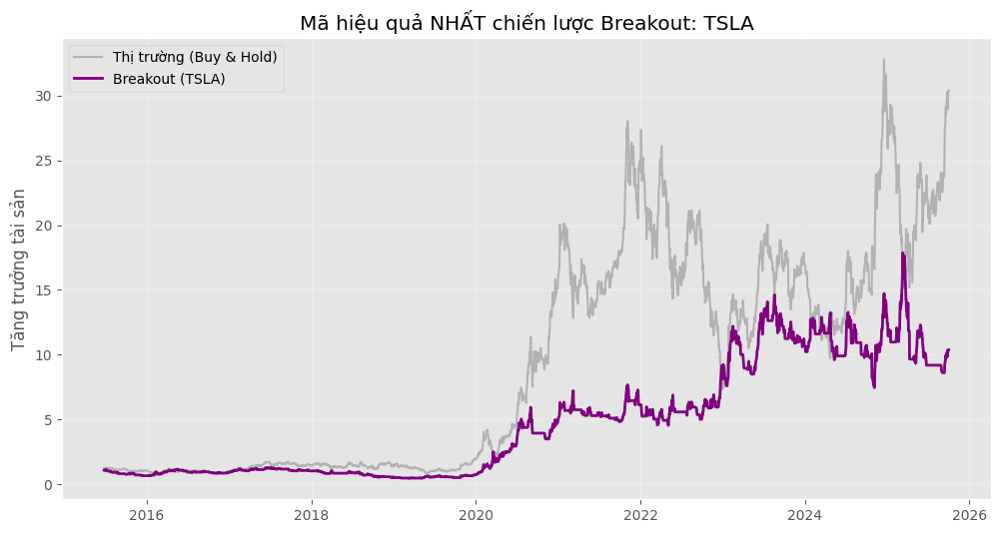


Tham khảo: Mã tệ nhất là NOW (Lãi: -92.08%)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def backtest_breakout(df, initial_capital= 100_000_000):
    # 1. Tìm tên cột giá chuẩn
    if 'Adj Close' in df.columns:
      col_price = 'Adj Close'
    elif 'Close' in df.columns:
      col_price = 'Close'
    elif 'Prev_Adj_Close' in df.columns:
      col_price = 'Prev_Adj_Close'
    else:
      return None

    if 'GARCH_Vol' not in df.columns:
      return None

    # 2. Tính toán Bands (Dựa trên GARCH)
    # Đường giữa (Trend Line)
    df['MA_20'] = df[col_price].rolling(window=20).mean()

    # Dải băng co giãn theo GARCH Volatility
    # Breakout cần dải băng chặt hơn chút để nhạy, hoặc rộng hơn để tránh nhiễu
    # Ở đây ta giữ nguyên chuẩn 2*Vol
    df['Upper_Band'] = df['MA_20'] * (1 + 2 * df['GARCH_Vol'])
    df['Lower_Band'] = df['MA_20'] * (1 - 2 * df['GARCH_Vol'])

    # 3. Logic Mua/Bán (Breakout Logic)
    # Signal = 1 (Long), -1 (Short), 0 (Cash)
    df['Signal'] = 0

    # ENTRY: Phá vỡ ra ngoài biên
    long_condition = df[col_price] > df['Upper_Band']
    short_condition = df[col_price] < df['Lower_Band']

    # EXIT: Giá quay đầu cắt lại đường MA (Trailing Stop)
    exit_long = df[col_price] < df['MA_20']
    exit_short = df[col_price] > df['MA_20']

    # 4. Xử lý trạng thái giữ lệnh (State Machine)
    # Breakout là chiến thuật theo Trend (Momentum), nên phải giữ lệnh lâu
    position = 0
    positions = []

    for i in range(len(df)):
        # Nếu đang không có lệnh (Cash)
        if position == 0:
            if long_condition.iloc[i]: position = 1   # Breakout lên -> Mua
            elif short_condition.iloc[i]: position = -1 # Breakout xuống -> Short

        # Nếu đang giữ Long
        elif position == 1:
            if exit_long.iloc[i]: position = 0        # Thủng MA -> Chốt

        # Nếu đang giữ Short
        elif position == -1:
            if exit_short.iloc[i]: position = 0       # Vượt MA -> Cắt

        positions.append(position)

    df['Position'] = positions

    # 5. Tính Lãi/Lỗ (Shift 1 ngày)
    df['Strategy_Returns'] = df['Position'].shift(1) * df['Log_Returns']

    # Tổng kết hiệu quả
    df['Cumulative_Strategy'] = df['Strategy_Returns'].cumsum().apply(np.exp)
    df['Cumulative_Market'] = df['Log_Returns'].cumsum().apply(np.exp)

    return df

# --- CHẠY BACKTEST ---
print("Đang chạy Backtest chiến lược Breakout...")
breakout_results = []

# Copy dữ liệu ra để không đè lên cái cũ
df_breakout = {k: v.copy() for k, v in df_signal_copy.items()}

for ticker, df in df_breakout.items():
    df_res = backtest_breakout(df)

    if df_res is not None and 'Cumulative_Strategy' in df_res.columns:
        total_ret = df_res['Cumulative_Strategy'].iloc[-1] - 1
        mkt_ret = df_res['Cumulative_Market'].iloc[-1] - 1

        breakout_results.append({
            'Ticker': ticker,
            'Breakout Return': total_ret,
            'Market Return': mkt_ret,
            'Hiệu Quả': total_ret > mkt_ret
        })
        # Lưu lại
        df_breakout[ticker] = df_res

# --- HIỂN THỊ KẾT QUẢ TOÀN BỘ ---
if breakout_results:
    df_perf = pd.DataFrame(breakout_results)

    # 1. Format số liệu dạng %
    pd.options.display.float_format = '{:,.2%}'.format

    # 2. Sắp xếp: Lời nhiều nhất lên đầu
    df_perf_sorted = df_perf.sort_values(by='Breakout Return', ascending=False)

    print(f"\n=== BẢNG KẾT QUẢ BREAKOUT TOÀN BỘ {len(df_perf_sorted)} MÃ ===")

    # --- QUAN TRỌNG: Dùng to_string() để in hết danh sách ---
    print(df_perf_sorted.to_string())

    # -----------------------------------------------------------------------
    # Vẽ biểu đồ mã TỐT NHẤT (để xem mẫu)
    best_ticker = df_perf_sorted.iloc[0]['Ticker']
    df_plot = df_breakout[best_ticker].dropna()

    plt.figure(figsize=(12, 6))
    plt.plot(df_plot.index, df_plot['Cumulative_Market'], label='Thị trường (Buy & Hold)', color='gray', alpha=0.5)
    plt.plot(df_plot.index, df_plot['Cumulative_Strategy'], label=f'Breakout ({best_ticker})', color='purple', lw=2)

    plt.title(f'Mã hiệu quả NHẤT chiến lược Breakout: {best_ticker}')
    plt.ylabel('Tăng trưởng tài sản')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # (Tùy chọn) Vẽ thêm mã TỆ NHẤT để rút kinh nghiệm
    worst_ticker = df_perf_sorted.iloc[-1]['Ticker']
    print(f"\nTham khảo: Mã tệ nhất là {worst_ticker} (Lãi: {df_perf_sorted.iloc[-1]['Breakout Return']:.2%})")

else:
    print("Không có dữ liệu.")